
# JATIKARYA
## Image Provenance Verification after Generative Editing Using Watermarks and Visual Matching

**Program:** Magister Sistem Informasi  
**Bidang:** Artificial Intelligence / Computer Vision  
**Jenis:** Penelitian individu S2  
**Platform:** Python & Google Colab  
**Target publikasi:** Minimal SINTA 2, aspirasi standar Scopus

### Tujuan Penelitian
Mengembangkan dan mengevaluasi sistem verifikasi asal gambar setelah pengeditan generatif menggunakan dua pendekatan:

1. **TrustMark:** Invisible watermarking untuk menyisipkan dan memeriksa identitas gambar.
2. **DINOv2:** Visual feature extraction untuk mencocokkan gambar dengan sumber terdaftar.

### Metode Evaluasi
- TrustMark-only
- DINOv2-only
- Naive Fusion
- Calibrated Fusion dengan conflict handling dan abstention

### Prinsip Penelitian
- Tidak membuat data atau hasil eksperimen palsu.
- Semua eksperimen harus dapat direproduksi.
- Pisahkan dataset development, calibration, dan final test.
- Catat konfigurasi, versi model, dan hasil pengujian.
- Tidak menyimpulkan novelty tanpa audit literatur.
- Semua keputusan penting memerlukan persetujuan peneliti.

### Status Awal
- Literature Verification: Belum ditutup
- Research Methodology: Draf v0.1
- Notebook 01: Persiapan lingkungan
- Eksperimen: Belum dijalankan
- Hasil penelitian: Belum tersedia


In [34]:
# JATIKARYA - STEP 01
# Research Workspace Initialization

from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone
import json

# Hubungkan penyimpanan permanen
drive.mount("/content/drive")

# Workspace baru, terpisah dari eksperimen lama
ROOT = Path("/content/drive/MyDrive/JATIKARYA_V2")

folders = [
    "00_GOVERNANCE",
    "01_DATASET/ORIGINAL",
    "01_DATASET/WATERMARKED",
    "01_DATASET/MANUAL_EDITS",
    "01_DATASET/GENERATIVE_EDITS",
    "02_EXPERIMENTS/TRUSTMARK",
    "02_EXPERIMENTS/DINOV2",
    "02_EXPERIMENTS/FUSION",
    "02_EXPERIMENTS/ROBUSTNESS",
    "03_RESULTS/PILOT",
    "03_RESULTS/FINAL",
    "04_LOGS",
    "05_NOTEBOOKS",
    "06_RESEARCH_BACKLOG"
]

for folder in folders:
    (ROOT / folder).mkdir(
        parents=True,
        exist_ok=True
    )

# Metadata penelitian
config_path = ROOT / "00_GOVERNANCE/project_config.json"

config = {
    "project": "JATIKARYA",
    "version": "2.0",
    "research_type": "Individual Master Research",
    "main_methods": ["TrustMark", "DINOv2"],
    "phase": "RESEARCH_FOUNDATION",
    "experiment_status": "NOT_STARTED",
    "old_pilot": "ARCHIVED_SEPARATELY",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

# Jangan timpa konfigurasi sebelumnya
if not config_path.exists():
    config_path.write_text(
        json.dumps(config, indent=4),
        encoding="utf-8"
    )

print("=== JATIKARYA V2 ===")
print("Workspace:", ROOT)
print("Folder tersedia:", len(folders))
print("Konfigurasi:", config_path)
print("STATUS: FOUNDATION INITIALIZED")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== JATIKARYA V2 ===
Workspace: /content/drive/MyDrive/JATIKARYA_V2
Folder tersedia: 14
Konfigurasi: /content/drive/MyDrive/JATIKARYA_V2/00_GOVERNANCE/project_config.json
STATUS: FOUNDATION INITIALIZED


In [37]:
# JATIKARYA - STEP 02
# Automatic Experiment Logging System v1.0

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import csv
import shutil
import uuid

ROOT = Path("/content/drive/MyDrive/JATIKARYA_V2")

assert ROOT.is_dir(), \
    "Workspace belum tersedia. Jalankan STEP 01 dahulu."

LOG_DIR = ROOT / "04_LOGS"
EXP_DIR = ROOT / "02_EXPERIMENTS"
BACKLOG_DIR = ROOT / "06_RESEARCH_BACKLOG"

for folder in [LOG_DIR, EXP_DIR, BACKLOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# 1. SHA256 untuk integritas file
def file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

# 2. Membuat eksperimen dengan ID unik
def start_experiment(step, method, parameters=None):
    now = datetime.now(timezone.utc)

    run_id = (
        now.strftime("%Y%m%dT%H%M%S%fZ")
        + "_" + uuid.uuid4().hex[:8]
    )

    run_dir = EXP_DIR / step / run_id

    run_dir.mkdir(parents=True, exist_ok=False)

    for subfolder in ["inputs", "outputs", "logs"]:
        (run_dir / subfolder).mkdir()

    metadata = {
        "project": "JATIKARYA",
        "run_id": run_id,
        "step": step,
        "method": method,
        "phase": "PILOT",
        "created_at_utc": now.isoformat(),
        "parameters": parameters or {},
        "status": "CREATED"
    }

    (run_dir / "metadata.json").write_text(
        json.dumps(metadata, indent=4),
        encoding="utf-8"
    )

    # Registri eksperimen
    index = LOG_DIR / "experiment_log.csv"
    is_new = not index.exists()

    with open(index, "a", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)

        if is_new:
            writer.writerow([
                "run_id", "timestamp_utc",
                "step", "method", "phase",
                "initial_status", "folder"
            ])

        writer.writerow([
            run_id,
            now.isoformat(),
            step,
            method,
            "PILOT",
            "CREATED",
            str(run_dir.relative_to(ROOT))
        ])

    return run_dir

# 3. Menyimpan file tanpa menimpa hasil lama
def archive_artifact(source, run_dir, category="outputs"):
    source = Path(source)
    run_dir = Path(run_dir)

    assert source.is_file(), f"File tidak ada: {source}"
    assert category in ("inputs", "outputs")

    destination = run_dir / category / source.name

    if destination.exists():
        raise FileExistsError(
            f"File sudah diarsipkan: {destination}"
        )

    shutil.copy2(source, destination)

    original_hash = file_hash(source)
    saved_hash = file_hash(destination)

    assert original_hash == saved_hash, \
        "Integritas file gagal!"

    record_event(run_dir, "FILE_ARCHIVED", {
        "path": str(destination.relative_to(ROOT)),
        "sha256": saved_hash
    })

    return destination

# 4. Mencatat hasil atau error
def record_event(run_dir, event, details):
    record = {
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "event": event,
        "details": details
    }

    log_path = Path(run_dir) / "logs" / "events.jsonl"

    with open(log_path, "a", encoding="utf-8") as f:
        f.write(
            json.dumps(record, ensure_ascii=False)
            + "\n"
        )

# 5. Simpan backlog brightness
backlog = BACKLOG_DIR / "BR-001_BRIGHTNESS.md"

if not backlog.exists():
    backlog.write_text(
        """# BR-001 - Brightness Robustness

Status: PENDING
Phase: PILOT EXPLORATION

Temuan:
- Kontras manual +20/+40: payload cocok.
- Brightness manual +20/+40: payload gagal.
- Pillow brightness 1.20: payload cocok.
- DINOv2 tetap menunjukkan similarity tinggi.

Evaluasi berikutnya:
1. Bandingkan algoritma brightness dan exposure.
2. Audit clipping dan perubahan piksel.
3. Uji pada banyak gambar sumber independen.
4. Evaluasi ketahanan watermark secara statistik.

Penyebab kegagalan belum terverifikasi.
Hasil lama tidak boleh diklaim sebagai hasil final.
""",
        encoding="utf-8"
    )

# 6. Tes sistem penyimpanan
test_run = start_experiment(
    step="STEP_02_STORAGE_TEST",
    method="SYSTEM_VALIDATION",
    parameters={"test_only": True}
)

test_source = Path("/content/JATIKARYA_storage_test.txt")
test_source.write_text(
    "JATIKARYA STORAGE TEST - NOT RESEARCH DATA",
    encoding="utf-8"
)

saved = archive_artifact(
    test_source, test_run, category="outputs"
)

record_event(test_run, "STORAGE_TEST", {
    "result": "PASS",
    "sha256_verified": True
})

print("=== JATIKARYA STEP 02 ===")
print("Workspace:", ROOT)
print("Experiment ID:", test_run.name)
print("File tersimpan:", saved.exists())
print("Hash cocok:",
      file_hash(test_source) == file_hash(saved))
print("Experiment log:", (LOG_DIR / "experiment_log.csv").exists())
print("Brightness backlog:", backlog.exists())
print("STATUS: STORAGE SYSTEM READY")


=== JATIKARYA STEP 02 ===
Workspace: /content/drive/MyDrive/JATIKARYA_V2
Experiment ID: 20261105T035759844058Z_326d89a2
File tersimpan: True
Hash cocok: True
Experiment log: True
Brightness backlog: True
STATUS: STORAGE SYSTEM READY


In [38]:

# JATIKARYA - STEP 03
# Source Image Registration v1.0

from google.colab import files
from pathlib import Path
from PIL import Image
from datetime import datetime, timezone
import pandas as pd
import shutil
import json

# 1. Upload satu gambar sumber ASLI
uploaded = files.upload()

assert len(uploaded) == 1, \
    "Unggah tepat satu gambar sumber."

filename = next(iter(uploaded))
source = Path(filename)

# 2. Validasi gambar tanpa mengubah file
with Image.open(source) as img:
    img.verify()

with Image.open(source) as img:
    width, height = img.size
    image_format = img.format

assert image_format in ("JPEG", "PNG", "WEBP"), \
    "Format gambar belum didukung."

# 3. Buat identitas unik berdasarkan SHA-256
sha256 = file_hash(source)
source_id = "SRC_" + sha256[:16]

# 4. Folder permanen per sumber
source_dir = ROOT / "01_DATASET/ORIGINAL" / source_id
source_dir.mkdir(parents=True, exist_ok=True)

destination = source_dir / source.name

# Jangan menimpa file lama
if destination.exists():
    assert file_hash(destination) == sha256, \
        "Konflik nama file dan hash!"
else:
    shutil.copy2(source, destination)

assert file_hash(destination) == sha256

# 5. Buat registrasi eksperimen
run_dir = start_experiment(
    step="STEP_03_SOURCE_REGISTRATION",
    method="SOURCE_REGISTRATION",
    parameters={
        "source_id": source_id,
        "sha256": sha256,
        "filename": filename
    }
)

archive_artifact(
    destination,
    run_dir,
    category="inputs"
)

# 6. Registri gambar sumber
registry_path = ROOT / "04_LOGS/source_registry.csv"

record = {
    "source_id": source_id,
    "filename": filename,
    "sha256": sha256,
    "width": width,
    "height": height,
    "format": image_format,
    "stored_path": str(destination.relative_to(ROOT)),
    "registered_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": "REGISTERED"
}

if registry_path.exists():
    registry_df = pd.read_csv(
        registry_path, dtype=str
    )
else:
    registry_df = pd.DataFrame(
        columns=list(record.keys())
    )

if source_id not in registry_df["source_id"].values:
    registry_df = pd.concat(
        [registry_df, pd.DataFrame([record])],
        ignore_index=True
    )
    registry_df.to_csv(registry_path, index=False)

# 7. Simpan metadata gambar
metadata_path = source_dir / "source_metadata.json"

if not metadata_path.exists():
    metadata_path.write_text(
        json.dumps(record, indent=4),
        encoding="utf-8"
    )

record_event(run_dir, "SOURCE_REGISTERED", {
    "source_id": source_id,
    "sha256": sha256,
    "stored_path": record["stored_path"]
})

# 8. Output validasi
print("=== JATIKARYA STEP 03 ===")
print("Source ID:", source_id)
print("Nama file:", filename)
print("Resolusi:", width, "x", height)
print("Format:", image_format)
print("SHA256:", sha256)
print("File permanen:", destination.exists())
print("Hash cocok:", file_hash(destination) == sha256)
print("Registry:", registry_path.exists())
print("STATUS: SOURCE REGISTERED")


Saving WhatsApp Image 2026-11-03 at 08.23.24.jpeg to WhatsApp Image 2026-11-03 at 08.23.24 (2).jpeg
=== JATIKARYA STEP 03 ===
Source ID: SRC_f2bac8171ed1e8e7
Nama file: WhatsApp Image 2026-11-03 at 08.23.24 (2).jpeg
Resolusi: 1086 x 1448
Format: JPEG
SHA256: f2bac8171ed1e8e70d8ac32b919af4e8d438c2852558a06eadf629802a8d03e9
File permanen: True
Hash cocok: True
Registry: True
STATUS: SOURCE REGISTERED


In [39]:
# JATIKARYA - STEP 04
# TrustMark Q + BCH_5
# Permanent Watermark Encoding & Validation

from trustmark import TrustMark
from PIL import Image, ImageOps
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import json
import shutil
import torch
import pandas as pd

# 1. Identitas sumber
SOURCE_ID = "SRC_f2bac8171ed1e8e7"

registry = pd.read_csv(
    ROOT / "04_LOGS/source_registry.csv",
    dtype=str
)

entry = registry.loc[
    registry["source_id"] == SOURCE_ID
]

assert len(entry) == 1, \
    "Source ID tidak ditemukan atau duplikat."

record = entry.iloc[0]

source_path = ROOT / record["stored_path"]

assert source_path.exists(), "Gambar sumber tidak ditemukan"
assert file_hash(source_path) == record["sha256"], \
    "Integritas gambar sumber gagal!"

# 2. Konfigurasi eksperimen
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MAX_SIZE = 768

parameters = {
    "source_id": SOURCE_ID,
    "model": "TrustMark-Q",
    "encoding": "BCH_5",
    "device": DEVICE,
    "max_dimension": MAX_SIZE,
    "trustmark_version": version("trustmark"),
    "source_sha256": record["sha256"]
}

# 3. Buat folder run unik
run_dir = start_experiment(
    step="STEP_04_TRUSTMARK_ENCODE",
    method="TrustMark-Q",
    parameters=parameters
)

try:
    # 4. Siapkan salinan, bukan mengubah asli
    with Image.open(source_path) as image:
        working_image = ImageOps.exif_transpose(
            image
        ).convert("RGB")

    working_image.thumbnail(
        (MAX_SIZE, MAX_SIZE),
        Image.Resampling.LANCZOS
    )

    input_path = run_dir / "inputs/source_prepared.png"
    working_image.save(input_path)

    # 5. Payload 61-bit dari SHA256 sumber asli
    source_hash = record["sha256"]

    payload_bits = bin(
        int(source_hash, 16)
    )[2:].zfill(256)[:61]

    assert len(payload_bits) == 61

    # Hindari payload sama pada sumber berbeda
    for _, other in registry.iterrows():
        if other["source_id"] != SOURCE_ID:
            other_bits = bin(
                int(other["sha256"], 16)
            )[2:].zfill(256)[:61]

            assert payload_bits != other_bits, \
                "Konflik payload antar sumber!"

    # 6. Inisialisasi TrustMark
    tm = TrustMark(
        verbose=True,
        model_type="Q",
        encoding_type=TrustMark.Encoding.BCH_5,
        device=DEVICE
    )

    # 7. Encoding watermark
    encoded_image = tm.encode(
        working_image,
        payload_bits,
        MODE="binary"
    )

    output_path = run_dir / "outputs/watermarked.png"

    encoded_image.save(output_path, format="PNG")

    # 8. Decode ulang dari file tersimpan
    with Image.open(output_path) as image:
        verification_image = image.convert("RGB")

    decoded, detected, schema = tm.decode(
        verification_image,
        MODE="binary"
    )

    payload_match = (
        bool(detected)
        and decoded == payload_bits
        and schema == TrustMark.Encoding.BCH_5
    )

    # 9. Folder permanen berdasarkan sumber
    wm_dir = (
        ROOT / "01_DATASET/WATERMARKED" / SOURCE_ID
    )

    wm_dir.mkdir(parents=True, exist_ok=True)

    permanent_path = (
        wm_dir / f"{run_dir.name}_watermarked.png"
    )

    shutil.copy2(output_path, permanent_path)

    assert file_hash(output_path) == file_hash(
        permanent_path
    )

    # 10. Metadata dan hasil verifikasi
    result = {
        "source_id": SOURCE_ID,
        "run_id": run_dir.name,
        "source_sha256": source_hash,
        "prepared_sha256": file_hash(input_path),
        "watermarked_sha256": file_hash(output_path),
        "payload_bits": payload_bits,
        "payload_length": len(payload_bits),
        "watermark_detected": bool(detected),
        "payload_match": bool(payload_match),
        "decoded_payload": decoded,
        "schema": int(schema) if schema is not None else None,
        "trustmark_version": version("trustmark"),
        "device": DEVICE,
        "image_resolution": list(working_image.size),
        "stored_path": str(permanent_path.relative_to(ROOT)),
        "phase": "PILOT",
        "status": "PASS" if payload_match else "FAIL",
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    result_path = (
        run_dir / "outputs/verification_result.json"
    )

    result_path.write_text(
        json.dumps(result, indent=2),
        encoding="utf-8"
    )

    record_event(run_dir, "ENCODE_DECODE_COMPLETED", result)

    # Update status run
    metadata_path = run_dir / "metadata.json"
    metadata = json.loads(metadata_path.read_text())
    metadata["status"] = result["status"]
    metadata["completed_at_utc"] = result["timestamp_utc"]
    metadata_path.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

    print("=== JATIKARYA STEP 04 ===")
    print("Source ID:", SOURCE_ID)
    print("Run ID:", run_dir.name)
    print("Payload:", len(payload_bits), "bit")
    print("Watermark detected:", detected)
    print("Payload match:", payload_match)
    print("Device:", DEVICE)
    print("File permanen:", permanent_path)
    print("STATUS:", result["status"])

except Exception as e:
    record_event(run_dir, "RUN_FAILED", {
        "error_type": type(e).__name__,
        "message": str(e)
    })

    metadata_path = run_dir / "metadata.json"
    metadata = json.loads(metadata_path.read_text())
    metadata["status"] = "ERROR"
    metadata_path.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )
    raise


Initializing TrustMark watermarking with ECC using [cpu]
=== JATIKARYA STEP 04 ===
Source ID: SRC_f2bac8171ed1e8e7
Run ID: 20261105T041554787936Z_b8c57050
Payload: 61 bit
Watermark detected: True
Payload match: True
Device: cpu
File permanen: /content/drive/MyDrive/JATIKARYA_V2/01_DATASET/WATERMARKED/SRC_f2bac8171ed1e8e7/20261105T041554787936Z_b8c57050_watermarked.png
STATUS: PASS


In [40]:
# JATIKARYA - STEP 05
# DINOv2 Feature Extraction & Permanent Logging

import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import numpy as np
import pandas as pd
import json
from pathlib import Path
from datetime import datetime, timezone

SOURCE_ID = "SRC_f2bac8171ed1e8e7"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# 1. Cari hasil TrustMark yang sudah lulus
step04_dir = ROOT / "02_EXPERIMENTS/STEP_04_TRUSTMARK_ENCODE"

candidates = []

for p in step04_dir.glob(
    "*/outputs/verification_result.json"
):
    data = json.loads(p.read_text())

    if (
        data.get("source_id") == SOURCE_ID
        and data.get("payload_match") is True
    ):
        candidates.append((p, data))

assert candidates, "Tidak ada hasil TrustMark PASS."

# Pilih run berhasil terbaru
result_path, wm_record = sorted(
    candidates, key=lambda x: x[0].parent.parent.name
)[-1]

step04_run = result_path.parent.parent

prepared_path = (
    step04_run / "inputs/source_prepared.png"
)

watermarked_path = (
    ROOT / wm_record["stored_path"]
)

# 2. Validasi file dan SHA256
assert prepared_path.exists()
assert watermarked_path.exists()

assert file_hash(prepared_path) == (
    wm_record["prepared_sha256"]
)

assert file_hash(watermarked_path) == (
    wm_record["watermarked_sha256"]
)

# 3. Buat run DINOv2
run05 = start_experiment(
    step="STEP_05_DINOV2_FEATURES",
    method="DINOv2-ViT-S14",
    parameters={
        "source_id": SOURCE_ID,
        "parent_run": step04_run.name,
        "model": "dinov2_vits14",
        "input_size": 518,
        "device": DEVICE
    }
)

try:
    # 4. Arsipkan input ke run
    archive_artifact(
        prepared_path, run05, "inputs"
    )

    archive_artifact(
        watermarked_path, run05, "inputs"
    )

    # 5. Muat pretrained model
    print("Memuat DINOv2 ViT-S/14...")

    dinov2 = torch.hub.load(
        "facebookresearch/dinov2",
        "dinov2_vits14",
        pretrained=True,
        trust_repo=True
    ).to(DEVICE).eval()

    # 6. Preprocessing yang konsisten
    preprocess = transforms.Compose([
        transforms.Resize(518),
        transforms.CenterCrop(518),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    def extract_embedding(path):
        with Image.open(path) as im:
            image = im.convert("RGB")
            tensor = preprocess(image).unsqueeze(0)
            tensor = tensor.to(DEVICE)

        with torch.inference_mode():
            features = dinov2(tensor)

        return F.normalize(
            features, p=2, dim=1
        ).cpu().numpy()[0].astype(np.float32)

    # 7. Ekstraksi embedding
    emb_prepared = extract_embedding(
        prepared_path
    )

    emb_watermarked = extract_embedding(
        watermarked_path
    )

    assert emb_prepared.shape == (384,)
    assert emb_watermarked.shape == (384,)
    assert np.isfinite(emb_prepared).all()
    assert np.isfinite(emb_watermarked).all()

    # 8. Cosine similarity
    similarity = float(
        np.dot(emb_prepared, emb_watermarked)
    )

    # 9. Simpan embedding asli
    output_dir = run05 / "outputs"

    np.save(
        output_dir / "embedding_prepared.npy",
        emb_prepared
    )

    np.save(
        output_dir / "embedding_watermarked.npy",
        emb_watermarked
    )

    # 10. Simpan hasil numerik
    result = {
        "source_id": SOURCE_ID,
        "run_id": run05.name,
        "parent_run": step04_run.name,
        "model": "DINOv2-ViT-S14",
        "embedding_dimension": 384,
        "preprocessing": "Resize518_CenterCrop518",
        "cosine_similarity": similarity,
        "prepared_sha256": file_hash(prepared_path),
        "watermarked_sha256": file_hash(watermarked_path),
        "device": DEVICE,
        "torch_version": torch.__version__,
        "phase": "PILOT",
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    result_file = output_dir / "similarity.json"

    result_file.write_text(
        json.dumps(result, indent=2),
        encoding="utf-8"
    )

    record_event(
        run05,
        "DINOV2_EXTRACTION_COMPLETED",
        result
    )

    # 11. Update status eksperimen
    metadata_file = run05 / "metadata.json"
    metadata = json.loads(metadata_file.read_text())
    metadata["status"] = "PASS"
    metadata["completed_at_utc"] = result["timestamp_utc"]

    metadata_file.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

    print("\n=== JATIKARYA STEP 05 ===")
    print("Source ID:", SOURCE_ID)
    print("Run ID:", run05.name)
    print("Embedding Dimension:", len(emb_prepared))
    print(f"Cosine Similarity: {similarity:.6f}")
    print("Embedding tersimpan:",
          (output_dir / "embedding_watermarked.npy").exists())
    print("Hasil JSON tersimpan:", result_file.exists())
    print("STATUS: PASS")

except Exception as e:
    record_event(run05, "RUN_FAILED", {
        "error_type": type(e).__name__,
        "message": str(e)
    })

    metadata_file = run05 / "metadata.json"
    metadata = json.loads(metadata_file.read_text())
    metadata["status"] = "ERROR"
    metadata_file.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )
    raise


Memuat DINOv2 ViT-S/14...


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main



=== JATIKARYA STEP 05 ===
Source ID: SRC_f2bac8171ed1e8e7
Run ID: 20261105T041952011024Z_bd87649c
Embedding Dimension: 384
Cosine Similarity: 0.994442
Embedding tersimpan: True
Hasil JSON tersimpan: True
STATUS: PASS


In [41]:
# JATIKARYA - STEP 06
# DINOv2 Visual Fingerprint Registry v1.0

from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import json

SOURCE_ID = "SRC_f2bac8171ed1e8e7"

# 1. Cari hasil DINOv2 yang berhasil
dinov2_root = ROOT / "02_EXPERIMENTS/STEP_05_DINOV2_FEATURES"

candidates = []

for result_file in dinov2_root.glob("*/outputs/similarity.json"):
    result = json.loads(result_file.read_text())

    run_folder = result_file.parent.parent
    metadata = json.loads(
        (run_folder / "metadata.json").read_text()
    )

    if (
        result.get("source_id") == SOURCE_ID
        and metadata.get("status") == "PASS"
    ):
        candidates.append((run_folder, result))

assert candidates, "Hasil DINOv2 PASS tidak ditemukan."

# 2. Pilih run berhasil terbaru
run_folder, result = sorted(
    candidates, key=lambda x: x[0].name
)[-1]

embedding_path = (
    run_folder / "outputs/embedding_watermarked.npy"
)

assert embedding_path.exists()

embedding = np.load(
    embedding_path, allow_pickle=False
)

assert embedding.shape == (384,)
assert np.isfinite(embedding).all()
assert np.isclose(np.linalg.norm(embedding), 1, atol=1e-4)

# 3. Verifikasi gambar yang menjadi referensi
parent_run = result["parent_run"]

wm_result_path = (
    ROOT / "02_EXPERIMENTS/STEP_04_TRUSTMARK_ENCODE"
    / parent_run / "outputs/verification_result.json"
)

wm_record = json.loads(wm_result_path.read_text())
assert wm_record["source_id"] == SOURCE_ID

image_path = ROOT / wm_record["stored_path"]

assert image_path.exists()
assert file_hash(image_path) == result["watermarked_sha256"]

# 4. Buat run registrasi
run06 = start_experiment(
    step="STEP_06_FEATURE_REGISTRY",
    method="DINOV2_REGISTRATION",
    parameters={
        "source_id": SOURCE_ID,
        "dinov2_run": run_folder.name
    }
)

# 5. Registri pusat
registry_path = (
    ROOT / "04_LOGS/dinov2_feature_registry.csv"
)

record = {
    "source_id": SOURCE_ID,
    "image_sha256": result["watermarked_sha256"],
    "model": result["model"],
    "preprocessing": result["preprocessing"],
    "embedding_dimension": 384,
    "embedding_path": str(
        embedding_path.relative_to(ROOT)
    ),
    "image_path": str(image_path.relative_to(ROOT)),
    "dinov2_run_id": run_folder.name,
    "registered_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

if registry_path.exists():
    registry_df = pd.read_csv(registry_path, dtype=str)
else:
    registry_df = pd.DataFrame(columns=record.keys())

# Hindari registrasi ganda dari run yang sama
duplicate = (
    registry_df["dinov2_run_id"] == run_folder.name
).any()

if not duplicate:
    registry_df = pd.concat(
        [registry_df, pd.DataFrame([record])],
        ignore_index=True
    )
    registry_df.to_csv(registry_path, index=False)

# 6. Simpan snapshot registrasi pada run STEP 06
snapshot_path = run06 / "outputs/registry_snapshot.csv"
registry_df.to_csv(snapshot_path, index=False)

record_event(run06, "FEATURE_REGISTERED", {
    "source_id": SOURCE_ID,
    "dinov2_run_id": run_folder.name,
    "duplicate_skipped": bool(duplicate),
    "embedding_sha256": file_hash(embedding_path)
})

metadata_path = run06 / "metadata.json"
metadata = json.loads(metadata_path.read_text())
metadata["status"] = "PASS"
metadata_path.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

print("=== JATIKARYA STEP 06 ===")
print("Source ID:", SOURCE_ID)
print("Embedding:", embedding.shape)
print("Norm:", round(float(np.linalg.norm(embedding)), 6))
print("Registri tersedia:", registry_path.exists())
print("Jumlah entri registri:", len(registry_df))
print("Duplikat dilewati:", duplicate)
print("STATUS: FEATURE REGISTERED")


=== JATIKARYA STEP 06 ===
Source ID: SRC_f2bac8171ed1e8e7
Embedding: (384,)
Norm: 1.0
Registri tersedia: True
Jumlah entri registri: 1
Duplikat dilewati: False
STATUS: FEATURE REGISTERED


In [42]:
# JATIKARYA - STEP 07
# Multi-Source Registration
# Permanent Storage & Audit Logging

from google.colab import files
from pathlib import Path
from PIL import Image
from datetime import datetime, timezone
import pandas as pd
import json
import shutil

print("=== JATIKARYA STEP 07 ===")
print("Unggah 3-5 gambar sumber independen.")

uploaded = files.upload()

assert len(uploaded) >= 2, \
    "Unggah minimal 2 gambar baru."

registry_path = ROOT / "04_LOGS/source_registry.csv"

registry_df = pd.read_csv(
    registry_path, dtype=str
)

# Buat run eksperimen baru
run07 = start_experiment(
    step="STEP_07_MULTI_SOURCE_REGISTRATION",
    method="BATCH_SOURCE_REGISTRATION",
    parameters={
        "uploaded_count": len(uploaded),
        "phase": "PILOT"
    }
)

# Simpan snapshot registri sebelum perubahan
shutil.copy2(
    registry_path,
    run07 / "inputs/source_registry_before.csv"
)

records = []

try:
    for filename in uploaded.keys():

        source = Path(filename)

        # Validasi format gambar
        with Image.open(source) as img:
            img.verify()

        with Image.open(source) as img:
            width, height = img.size
            image_format = img.format

        assert image_format in ("JPEG", "PNG", "WEBP")

        # Identitas berbasis hash
        sha256 = file_hash(source)
        source_id = "SRC_" + sha256[:16]

        # Hindari konflik identitas
        existing_id = registry_df[
            registry_df["source_id"] == source_id
        ]

        if not existing_id.empty:
            assert (
                existing_id["sha256"] == sha256
            ).all(), "Konflik Source ID!"

            print("Duplikat dilewati:", filename)
            continue

        # Simpan gambar asli secara permanen
        source_dir = (
            ROOT / "01_DATASET/ORIGINAL" / source_id
        )

        source_dir.mkdir(
            parents=True, exist_ok=True
        )

        destination = source_dir / source.name

        if not destination.exists():
            shutil.copy2(source, destination)

        assert file_hash(destination) == sha256

        # Arsipkan input dalam folder eksperimen
        archive_artifact(
            source,
            run07,
            category="inputs"
        )

        record = {
            "source_id": source_id,
            "filename": filename,
            "sha256": sha256,
            "width": width,
            "height": height,
            "format": image_format,
            "stored_path": str(
                destination.relative_to(ROOT)
            ),
            "registered_at_utc": datetime.now(
                timezone.utc
            ).isoformat(),
            "status": "REGISTERED"
        }

        # Metadata per sumber
        metadata_path = (
            source_dir / "source_metadata.json"
        )

        if not metadata_path.exists():
            metadata_path.write_text(
                json.dumps({
                    **record,
                    "source_family_id": source_id,
                    "independence_status":
                        "PENDING_VERIFICATION",
                    "rights_status":
                        "PENDING_CONFIRMATION"
                }, indent=2),
                encoding="utf-8"
            )

        records.append(record)

        record_event(
            run07,
            "SOURCE_REGISTERED",
            record
        )

    # Perbarui registry pusat
    if records:
        new_df = pd.DataFrame(records)

        registry_df = pd.concat(
            [registry_df, new_df],
            ignore_index=True
        )

        registry_df.to_csv(
            registry_path, index=False
        )

    # Snapshot hasil registrasi
    registry_df.to_csv(
        run07 / "outputs/registry_after.csv",
        index=False
    )

    metadata_file = run07 / "metadata.json"
    metadata = json.loads(metadata_file.read_text())
    metadata["status"] = "PASS"

    metadata_file.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

    print("\n=== HASIL STEP 07 ===")
    print("Sumber baru:", len(records))
    print("Total terdaftar:", len(registry_df))
    print("Registry tersimpan:", registry_path.exists())

    display(registry_df[[
        "source_id",
        "filename",
        "width",
        "height",
        "status"
    ]])

    print("STATUS: MULTI-SOURCE REGISTERED")

except Exception as e:
    record_event(run07, "RUN_FAILED", {
        "error_type": type(e).__name__,
        "message": str(e)
    })
    raise


=== JATIKARYA STEP 07 ===
Unggah 3-5 gambar sumber independen.


Saving IMG_8790.jpg to IMG_8790.jpg
Saving IMG_8791.jpg to IMG_8791.jpg
Saving IMG_8802.jpg to IMG_8802.jpg

=== HASIL STEP 07 ===
Sumber baru: 3
Total terdaftar: 4
Registry tersimpan: True


,source_id,filename,width,height,status
0,SRC_f2bac8171ed1e8e7,WhatsApp Image 2026-11-03 at 08.23.24 (2).jpeg,1086,1448,REGISTERED
1,SRC_0174ac57b5e15855,IMG_8790.jpg,1980,3520,REGISTERED
2,SRC_4d3a89996ab02369,IMG_8791.jpg,1980,3520,REGISTERED
3,SRC_7aa46b7fdad8909c,IMG_8802.jpg,1980,3520,REGISTERED


STATUS: MULTI-SOURCE REGISTERED


In [43]:
# JATIKARYA - STEP 08
# Multi-Source TrustMark Encoding
# PILOT - Permanent Storage & Logging

from trustmark import TrustMark
from PIL import Image, ImageOps
from pathlib import Path
from importlib.metadata import version
from datetime import datetime, timezone
import pandas as pd
import torch
import json
import shutil
import uuid

# 1. Konfigurasi
SOURCE_A = "SRC_f2bac8171ed1e8e7"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MAX_SIZE = 768

registry = pd.read_csv(
    ROOT / "04_LOGS/source_registry.csv",
    dtype=str
)

assert registry["source_id"].is_unique
assert SOURCE_A in registry["source_id"].values

# 2. Buat payload unik berdasarkan SHA-256
def get_payload(sha256):
    return bin(int(sha256, 16))[2:].zfill(256)[:61]

payload_map = {
    row["source_id"]: get_payload(row["sha256"])
    for _, row in registry.iterrows()
}

assert len(set(payload_map.values())) == len(payload_map), \
    "Konflik payload antar sumber!"

# 3. Hanya proses sumber B, C, D
new_sources = registry[
    registry["source_id"] != SOURCE_A
].copy()

assert len(new_sources) > 0

step_dir = ROOT / "02_EXPERIMENTS/STEP_08_TRUSTMARK_MULTI"

# 4. Periksa hasil PASS sebelumnya
def already_completed(source_id, source_hash):
    for p in step_dir.glob(
        "*/outputs/verification_result.json"
    ):
        try:
            data = json.loads(p.read_text())
            saved = ROOT / data["stored_path"]

            if (
                data.get("source_id") == source_id
                and data.get("source_sha256") == source_hash
                and data.get("payload_match") is True
                and data.get("model") == "TrustMark-Q"
                and data.get("encoding") == "BCH_5"
                and saved.exists()
                and file_hash(saved) == data["watermarked_sha256"]
            ):
                return True
        except (KeyError, ValueError, OSError):
            continue

    return False

# 5. Inisialisasi TrustMark satu kali
tm_multi = TrustMark(
    verbose=True,
    model_type="Q",
    encoding_type=TrustMark.Encoding.BCH_5,
    device=DEVICE
)

results = []

for _, row in new_sources.iterrows():

    source_id = row["source_id"]
    source_path = ROOT / row["stored_path"]
    source_hash = row["sha256"]
    payload = payload_map[source_id]

    assert source_path.exists()
    assert file_hash(source_path) == source_hash

    if already_completed(source_id, source_hash):
        print("Sudah PASS, dilewati:", source_id)
        results.append({
            "source_id": source_id,
            "status": "SKIPPED_ALREADY_PASS"
        })
        continue

    # 6. Folder run unik per sumber
    run = start_experiment(
        step="STEP_08_TRUSTMARK_MULTI",
        method="TrustMark-Q",
        parameters={
            "source_id": source_id,
            "source_sha256": source_hash,
            "encoding": "BCH_5",
            "payload_bits": payload,
            "max_dimension": MAX_SIZE,
            "device": DEVICE,
            "trustmark_version": version("trustmark")
        }
    )

    try:
        # Arsip gambar asli sebagai input
        archive_artifact(
            source_path, run, "inputs"
        )

        # 7. Siapkan salinan RGB
        with Image.open(source_path) as img:
            prepared = ImageOps.exif_transpose(
                img
            ).convert("RGB")

        prepared.thumbnail(
            (MAX_SIZE, MAX_SIZE),
            Image.Resampling.LANCZOS
        )

        prepared_path = run / "inputs/prepared.png"
        prepared.save(prepared_path)

        # 8. Sisipkan watermark
        encoded = tm_multi.encode(
            prepared,
            payload,
            MODE="binary"
        )

        output = run / "outputs/watermarked.png"
        encoded.save(output, format="PNG")

        # 9. Baca kembali hasil tersimpan
        with Image.open(output) as img:
            test_image = img.convert("RGB")

        decoded, detected, schema = tm_multi.decode(
            test_image,
            MODE="binary"
        )

        match = (
            bool(detected)
            and decoded == payload
            and schema == TrustMark.Encoding.BCH_5
        )

        # 10. Arsip permanen hanya untuk hasil PASS
        permanent = None

        if match:
            wm_dir = (
                ROOT / "01_DATASET/WATERMARKED" / source_id
            )
            wm_dir.mkdir(parents=True, exist_ok=True)

            permanent = (
                wm_dir / f"{run.name}_watermarked.png"
            )

            shutil.copy2(output, permanent)

            assert file_hash(output) == file_hash(permanent)

        # 11. Rekam hasil, termasuk kegagalan
        result = {
            "source_id": source_id,
            "run_id": run.name,
            "source_sha256": source_hash,
            "prepared_sha256": file_hash(prepared_path),
            "watermarked_sha256": file_hash(output),
            "payload_bits": payload,
            "decoded_payload": decoded,
            "watermark_detected": bool(detected),
            "payload_match": bool(match),
            "schema": int(schema) if schema is not None else None,
            "model": "TrustMark-Q",
            "encoding": "BCH_5",
            "trustmark_version": version("trustmark"),
            "device": DEVICE,
            "resolution": list(prepared.size),
            "stored_path": (
                str(permanent.relative_to(ROOT))
                if permanent else None
            ),
            "phase": "PILOT",
            "status": "PASS" if match else "FAILED_VALIDATION",
            "timestamp_utc": datetime.now(
                timezone.utc
            ).isoformat()
        }

        result_file = (
            run / "outputs/verification_result.json"
        )
        result_file.write_text(
            json.dumps(result, indent=2),
            encoding="utf-8"
        )

        record_event(run, "TRUSTMARK_VALIDATION", result)

        metadata_path = run / "metadata.json"
        metadata = json.loads(metadata_path.read_text())
        metadata["status"] = result["status"]
        metadata["completed_at_utc"] = result["timestamp_utc"]

        metadata_path.write_text(
            json.dumps(metadata, indent=2),
            encoding="utf-8"
        )

        results.append({
            "source_id": source_id,
            "detected": bool(detected),
            "payload_match": bool(match),
            "status": result["status"]
        })

        print(source_id, ":", result["status"])

    except Exception as e:
        record_event(run, "RUN_FAILED", {
            "error_type": type(e).__name__,
            "message": str(e)
        })

        metadata_path = run / "metadata.json"
        metadata = json.loads(metadata_path.read_text())
        metadata["status"] = "ERROR"
        metadata_path.write_text(
            json.dumps(metadata, indent=2),
            encoding="utf-8"
        )
        raise

# 12. Ringkasan permanen
summary = pd.DataFrame(results)

summary_dir = ROOT / "03_RESULTS/PILOT"
summary_dir.mkdir(parents=True, exist_ok=True)

summary_file = summary_dir / (
    "STEP08_" + uuid.uuid4().hex[:12] + ".csv"
)

summary.to_csv(summary_file, index=False)

print("\n=== JATIKARYA STEP 08 ===")
display(summary)
print("Ringkasan:", summary_file)
print("STATUS: MULTI-SOURCE ENCODING SELESAI")


Initializing TrustMark watermarking with ECC using [cpu]
SRC_0174ac57b5e15855 : PASS
SRC_4d3a89996ab02369 : PASS
SRC_7aa46b7fdad8909c : PASS

=== JATIKARYA STEP 08 ===


,source_id,detected,payload_match,status
0,SRC_0174ac57b5e15855,True,True,PASS
1,SRC_4d3a89996ab02369,True,True,PASS
2,SRC_7aa46b7fdad8909c,True,True,PASS


Ringkasan: /content/drive/MyDrive/JATIKARYA_V2/03_RESULTS/PILOT/STEP08_f474d018f8a7.csv
STATUS: MULTI-SOURCE ENCODING SELESAI


In [44]:
# JATIKARYA - STEP 09
# Multi-Source DINOv2 Feature Extraction
# PILOT V2 - Permanent Storage

import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import numpy as np
import pandas as pd
import json
from pathlib import Path
from datetime import datetime, timezone

SOURCE_A = "SRC_f2bac8171ed1e8e7"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_NAME = "dinov2_vits14"
PREPROCESS_ID = "Resize518_CenterCrop518"

# 1. Baca registri sumber
sources = pd.read_csv(
    ROOT / "04_LOGS/source_registry.csv",
    dtype=str
)

new_sources = sources[
    sources["source_id"] != SOURCE_A
].copy()

assert len(new_sources) == 3, \
    "Jumlah sumber baru tidak sesuai."

# 2. Registri fitur permanen
registry_path = (
    ROOT / "04_LOGS/dinov2_feature_registry.csv"
)

assert registry_path.exists(), \
    "Registri STEP 06 tidak ditemukan."

# 3. Muat model satu kali
print("Memuat DINOv2 ViT-S/14...")

model09 = torch.hub.load(
    "facebookresearch/dinov2",
    MODEL_NAME,
    pretrained=True,
    trust_repo=True
).to(DEVICE).eval()

# Catat identitas file bobot jika tersedia
weights_path = (
    Path(torch.hub.get_dir())
    / "checkpoints/dinov2_vits14_pretrain.pth"
)

weights_hash = (
    file_hash(weights_path)
    if weights_path.exists()
    else None
)

# 4. Preprocessing sesuai STEP 05
preprocess09 = transforms.Compose([
    transforms.Resize(518),
    transforms.CenterCrop(518),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def extract09(path):
    with Image.open(path) as img:
        tensor = preprocess09(
            img.convert("RGB")
        ).unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        embedding = model09(tensor)

    embedding = F.normalize(
        embedding, p=2, dim=1
    )

    return embedding.cpu().numpy()[0].astype(
        np.float32
    )

# 5. Proses ketiga sumber
summary09 = []

for _, source in new_sources.iterrows():

    sid = source["source_id"]

    # Cari TrustMark PASS dari STEP 08
    wm_root = (
        ROOT / "02_EXPERIMENTS"
        / "STEP_08_TRUSTMARK_MULTI"
    )

    candidates = []

    for p in wm_root.glob(
        "*/outputs/verification_result.json"
    ):
        d = json.loads(p.read_text())

        if (
            d.get("source_id") == sid
            and d.get("payload_match") is True
            and d.get("source_sha256") == source["sha256"]
        ):
            candidates.append((p, d))

    assert candidates, f"TrustMark PASS tidak ada: {sid}"

    wm_json, wm_data = sorted(
        candidates, key=lambda x: x[0].parent.parent.name
    )[-1]

    wm_run = wm_json.parent.parent

    prepared = wm_run / "inputs/prepared.png"
    watermarked = ROOT / wm_data["stored_path"]

    # Verifikasi integritas
    assert file_hash(prepared) == wm_data["prepared_sha256"]
    assert file_hash(watermarked) == wm_data["watermarked_sha256"]

    # Cek duplikasi hasil yang valid
    current = pd.read_csv(registry_path, dtype=str)

    existing = current[
        (current["source_id"] == sid)
        & (current["image_sha256"] == wm_data["watermarked_sha256"])
        & (current["model"] == "DINOv2-ViT-S14")
        & (current["preprocessing"] == PREPROCESS_ID)
    ]

    if not existing.empty:
        valid_existing = False

        for _, old in existing.iterrows():
            old_path = ROOT / old["embedding_path"]

            if old_path.exists():
                emb = np.load(
                    old_path, allow_pickle=False
                )

                if (
                    emb.shape == (384,)
                    and np.isfinite(emb).all()
                    and np.isclose(
                        np.linalg.norm(emb), 1,
                        atol=1e-4
                    )
                ):
                    valid_existing = True
                    break

        if valid_existing:
            print("Sudah terdaftar:", sid)
            summary09.append({
                "source_id": sid,
                "similarity": None,
                "status": "SKIPPED_EXISTING"
            })
            continue

        raise ValueError(
            f"Registri lama tidak valid: {sid}"
        )

    # 6. Buat folder eksperimen unik
    run = start_experiment(
        step="STEP_09_DINOV2_MULTI",
        method="DINOv2-ViT-S14",
        parameters={
            "source_id": sid,
            "parent_run": wm_run.name,
            "model": MODEL_NAME,
            "preprocessing": PREPROCESS_ID,
            "weights_sha256": weights_hash,
            "device": DEVICE
        }
    )

    try:
        # Arsip input ke folder run
        archive_artifact(prepared, run, "inputs")
        archive_artifact(watermarked, run, "inputs")

        # 7. Ekstraksi fitur
        emb_prepared = extract09(prepared)
        emb_wm = extract09(watermarked)

        for emb in [emb_prepared, emb_wm]:
            assert emb.shape == (384,)
            assert np.isfinite(emb).all()
            assert np.isclose(
                np.linalg.norm(emb), 1,
                atol=1e-4
            )

        similarity = float(
            np.dot(emb_prepared, emb_wm)
        )

        # 8. Simpan embedding
        out = run / "outputs"

        np.save(
            out / "embedding_prepared.npy",
            emb_prepared
        )
        np.save(
            out / "embedding_watermarked.npy",
            emb_wm
        )

        # Periksa hasil simpan
        check = np.load(
            out / "embedding_watermarked.npy",
            allow_pickle=False
        )

        assert np.array_equal(check, emb_wm)

        # 9. Catat hasil eksperimen
        result = {
            "source_id": sid,
            "run_id": run.name,
            "parent_run": wm_run.name,
            "model": "DINOv2-ViT-S14",
            "preprocessing": PREPROCESS_ID,
            "embedding_dimension": 384,
            "cosine_similarity": similarity,
            "image_sha256": file_hash(watermarked),
            "weights_sha256": weights_hash,
            "torch_version": torch.__version__,
            "device": DEVICE,
            "phase": "PILOT",
            "timestamp_utc": datetime.now(
                timezone.utc
            ).isoformat(),
            "status": "PASS"
        }

        (out / "similarity.json").write_text(
            json.dumps(result, indent=2),
            encoding="utf-8"
        )

        record_event(
            run, "DINOV2_EXTRACTION_COMPLETED", result
        )

        # 10. Daftarkan embedding
        record = {
            "source_id": sid,
            "image_sha256": result["image_sha256"],
            "model": result["model"],
            "preprocessing": PREPROCESS_ID,
            "embedding_dimension": 384,
            "embedding_path": str(
                (out / "embedding_watermarked.npy")
                .relative_to(ROOT)
            ),
            "image_path": str(
                watermarked.relative_to(ROOT)
            ),
            "dinov2_run_id": run.name,
            "registered_at_utc": result["timestamp_utc"]
        }

        # Simpan snapshot sebelum perubahan
        current.to_csv(
            run / "inputs/registry_before.csv",
            index=False
        )

        updated = pd.concat(
            [current, pd.DataFrame([record])],
            ignore_index=True
        )

        updated.to_csv(
            run / "outputs/registry_after.csv",
            index=False
        )

        updated.to_csv(
            registry_path, index=False
        )

        # Status run
        metadata_path = run / "metadata.json"
        metadata = json.loads(metadata_path.read_text())
        metadata["status"] = "PASS"
        metadata["completed_at_utc"] = result["timestamp_utc"]

        metadata_path.write_text(
            json.dumps(metadata, indent=2),
            encoding="utf-8"
        )

        summary09.append({
            "source_id": sid,
            "similarity": round(similarity, 6),
            "status": "PASS"
        })

        print(sid, ": PASS")

    except Exception as e:
        record_event(run, "RUN_FAILED", {
            "error_type": type(e).__name__,
            "message": str(e)
        })

        metadata_path = run / "metadata.json"
        metadata = json.loads(metadata_path.read_text())
        metadata["status"] = "ERROR"
        metadata_path.write_text(
            json.dumps(metadata, indent=2),
            encoding="utf-8"
        )
        raise

# 11. Ringkasan akhir
summary_df09 = pd.DataFrame(summary09)

print("\n=== JATIKARYA STEP 09 ===")
display(summary_df09)

final_registry = pd.read_csv(
    registry_path, dtype=str
)

print("Total embedding terdaftar:",
      final_registry["source_id"].nunique())

print("Bobot model teridentifikasi:",
      weights_hash is not None)

print("STATUS: MULTI-SOURCE FEATURES COMPLETED")


Memuat DINOv2 ViT-S/14...


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


SRC_0174ac57b5e15855 : PASS
SRC_4d3a89996ab02369 : PASS
SRC_7aa46b7fdad8909c : PASS

=== JATIKARYA STEP 09 ===


,source_id,similarity,status
0,SRC_0174ac57b5e15855,0.996155,PASS
1,SRC_4d3a89996ab02369,0.996441,PASS
2,SRC_7aa46b7fdad8909c,0.998702,PASS


Total embedding terdaftar: 4
Bobot model teridentifikasi: True
STATUS: MULTI-SOURCE FEATURES COMPLETED


In [45]:
# JATIKARYA - STEP 10
# Multi-Source Visual Matching
# PILOT - Open-Set Attribution Preparation

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageOps
from torchvision import transforms
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import json

# 1. Registri sumber dan fingerprint
sources = pd.read_csv(
    ROOT / "04_LOGS/source_registry.csv",
    dtype=str
)

features = pd.read_csv(
    ROOT / "04_LOGS/dinov2_feature_registry.csv",
    dtype=str
)

assert len(sources) == 4
assert sources["source_id"].is_unique
assert features["source_id"].is_unique
assert set(sources.source_id) == set(features.source_id)
assert (features["model"] == "DINOv2-ViT-S14").all()
assert (
    features["preprocessing"] ==
    "Resize518_CenterCrop518"
).all()

# 2. Muat model dengan konfigurasi yang sama
device10 = "cuda" if torch.cuda.is_available() else "cpu"

model10 = globals().get("model09")

if model10 is None:
    model10 = torch.hub.load(
        "facebookresearch/dinov2",
        "dinov2_vits14",
        pretrained=True,
        trust_repo=True
    )

model10 = model10.to(device10).eval()

weights_path = (
    Path(torch.hub.get_dir())
    / "checkpoints/dinov2_vits14_pretrain.pth"
)

assert weights_path.exists(), "Bobot model tidak ditemukan"
weights_sha256 = file_hash(weights_path)

preprocess10 = transforms.Compose([
    transforms.Resize(518),
    transforms.CenterCrop(518),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def embedding10(path):
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
        tensor = preprocess10(img).unsqueeze(0).to(device10)

    with torch.inference_mode():
        vector = model10(tensor)
        vector = F.normalize(vector, p=2, dim=1)

    return vector.cpu().numpy()[0].astype(np.float32)

# 3. Mulai eksperimen dan arsip registri
run10 = start_experiment(
    step="STEP_10_MULTI_SOURCE_MATCHING",
    method="DINOv2-ViT-S14",
    parameters={
        "source_count": 4,
        "query_type": "ORIGINAL_PRE_WATERMARK",
        "reference_type": "WATERMARKED",
        "weights_sha256": weights_sha256,
        "phase": "PILOT"
    }
)

try:
    archive_artifact(
        ROOT / "04_LOGS/source_registry.csv",
        run10, "inputs"
    )

    archive_artifact(
        ROOT / "04_LOGS/dinov2_feature_registry.csv",
        run10, "inputs"
    )

    # 4. Muat embedding referensi dan validasi model
    reference_vectors = {}
    query_vectors = {}
    input_records = []

    source_ids = sources["source_id"].tolist()
    labels = {
        sid: chr(65 + i)
        for i, sid in enumerate(source_ids)
    }

    for _, row in sources.iterrows():
        sid = row["source_id"]

        ref_row = features.loc[
            features.source_id == sid
        ].iloc[0]

        original = ROOT / row["stored_path"]
        wm_image = ROOT / ref_row["image_path"]
        embedding_file = ROOT / ref_row["embedding_path"]

        assert file_hash(original) == row["sha256"]
        assert file_hash(wm_image) == ref_row["image_sha256"]
        assert embedding_file.exists()

        saved_vector = np.load(
            embedding_file,
            allow_pickle=False
        )

        assert saved_vector.shape == (384,)
        assert np.isfinite(saved_vector).all()

        # Periksa konsistensi embedding dari model saat ini
        recomputed = embedding10(wm_image)

        max_difference = float(
            np.max(np.abs(saved_vector - recomputed))
        )

        if not np.allclose(
            saved_vector, recomputed,
            rtol=1e-4, atol=1e-4
        ):
            raise ValueError(
                f"Embedding tidak konsisten: {sid}"
            )

        reference_vectors[sid] = saved_vector
        query_vectors[sid] = embedding10(original)

        input_records.append({
            "source_id": sid,
            "label": labels[sid],
            "original_sha256": file_hash(original),
            "watermarked_sha256": file_hash(wm_image),
            "embedding_sha256": file_hash(embedding_file),
            "max_embedding_difference": max_difference
        })

    # 5. Bandingkan setiap query dengan semua sumber
    comparisons = []
    ranking_records = []

    for query_id in source_ids:
        scores = []

        for candidate_id in source_ids:
            similarity = float(np.dot(
                query_vectors[query_id],
                reference_vectors[candidate_id]
            ))

            comparisons.append({
                "query_id": query_id,
                "candidate_id": candidate_id,
                "query_label": labels[query_id],
                "candidate_label": labels[candidate_id],
                "similarity": similarity,
                "is_true_source": query_id == candidate_id
            })

            scores.append((candidate_id, similarity))

        scores.sort(key=lambda x: x[1], reverse=True)

        predicted_id = scores[0][0]

        ranking_records.append({
            "query": labels[query_id],
            "true_source": query_id,
            "predicted_source": predicted_id,
            "predicted_label": labels[predicted_id],
            "top1_score": scores[0][1],
            "top2_score": scores[1][1],
            "ranking_margin": scores[0][1] - scores[1][1],
            "correct_at_1": predicted_id == query_id
        })

    scores_df = pd.DataFrame(comparisons)
    ranking_df = pd.DataFrame(ranking_records)

    matrix = scores_df.pivot(
        index="query_label",
        columns="candidate_label",
        values="similarity"
    ).reindex(index=list("ABCD"), columns=list("ABCD"))

    # 6. Simpan hasil permanen
    output_dir = run10 / "outputs"

    scores_df.to_csv(
        output_dir / "all_pair_scores.csv",
        index=False
    )

    ranking_df.to_csv(
        output_dir / "rankings.csv",
        index=False
    )

    matrix.to_csv(
        output_dir / "similarity_matrix.csv"
    )

    pd.DataFrame(input_records).to_csv(
        output_dir / "input_integrity.csv",
        index=False
    )

    summary = {
        "run_id": run10.name,
        "phase": "PILOT",
        "query_type": "ORIGINAL_PRE_WATERMARK",
        "number_of_sources": len(source_ids),
        "number_of_comparisons": len(comparisons),
        "correct_at_1_count": int(ranking_df.correct_at_1.sum()),
        "weights_sha256": weights_sha256,
        "threshold_calibrated": False,
        "generative_editing_test": False,
        "created_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    (output_dir / "summary.json").write_text(
        json.dumps(summary, indent=2),
        encoding="utf-8"
    )

    record_event(run10, "MATCHING_COMPLETED", summary)

    metadata_path = run10 / "metadata.json"
    metadata = json.loads(metadata_path.read_text())
    metadata["status"] = "COMPLETED"
    metadata_path.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

    # 7. Tampilkan hasil
    print("=== JATIKARYA STEP 10 ===")
    print("\nSIMILARITY MATRIX")
    display(matrix.round(6))

    print("\nSOURCE RANKING")
    display(ranking_df)

    print(
        "Correct Rank@1:",
        f"{summary['correct_at_1_count']}/{len(source_ids)}"
    )
    print("File tersimpan:", output_dir)
    print("STATUS: MULTI-SOURCE TEST COMPLETED")

except Exception as e:
    record_event(run10, "RUN_FAILED", {
        "error_type": type(e).__name__,
        "message": str(e)
    })

    metadata_path = run10 / "metadata.json"
    metadata = json.loads(metadata_path.read_text())
    metadata["status"] = "ERROR"
    metadata_path.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )
    raise


=== JATIKARYA STEP 10 ===

SIMILARITY MATRIX


candidate_label,A,B,C,D
query_label,,,,
A,0.994404,-0.008776,-0.018045,-0.055663
B,-0.008175,0.988348,0.946661,0.287193
C,-0.012402,0.953423,0.988979,0.291701
D,-0.048797,0.333205,0.332273,0.995730



SOURCE RANKING


,query,true_source,predicted_source,predicted_label,top1_score,top2_score,ranking_margin,correct_at_1
0,A,SRC_f2bac8171ed1e8e7,SRC_f2bac8171ed1e8e7,A,0.994404,-0.008776,1.003180,True
1,B,SRC_0174ac57b5e15855,SRC_0174ac57b5e15855,B,0.988348,0.946661,0.041687,True
2,C,SRC_4d3a89996ab02369,SRC_4d3a89996ab02369,C,0.988979,0.953423,0.035556,True
3,D,SRC_7aa46b7fdad8909c,SRC_7aa46b7fdad8909c,D,0.995730,0.333205,0.662525,True


Correct Rank@1: 4/4
File tersimpan: /content/drive/MyDrive/JATIKARYA_V2/02_EXPERIMENTS/STEP_10_MULTI_SOURCE_MATCHING/20261105T044558409989Z_17d89435/outputs
STATUS: MULTI-SOURCE TEST COMPLETED


=== JATIKARYA STEP 11 ===


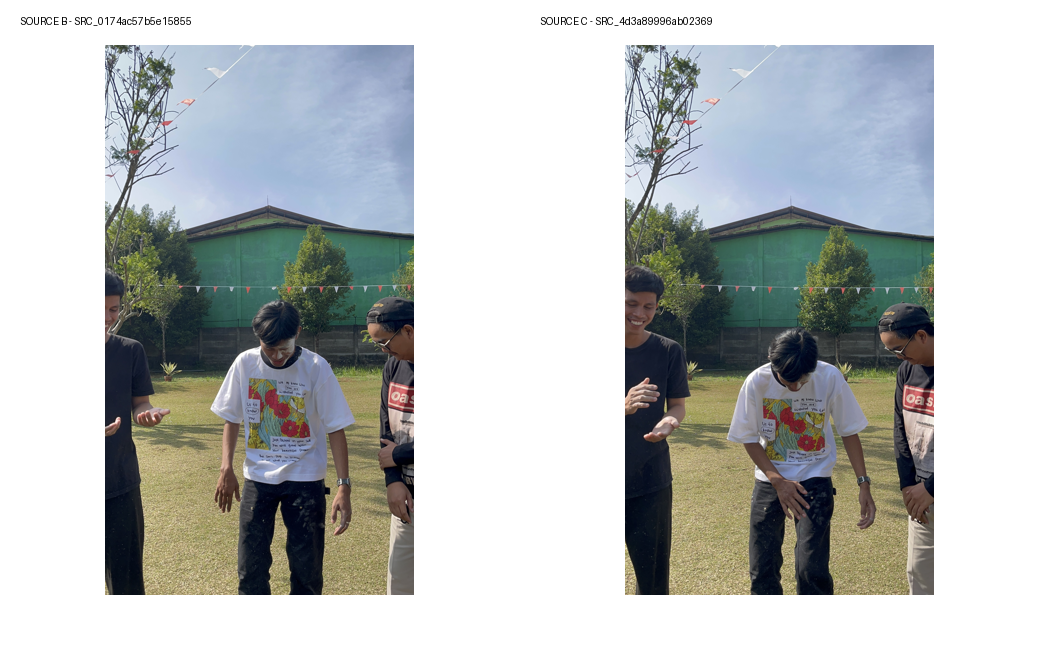

File tersimpan: /content/drive/MyDrive/JATIKARYA_V2/02_EXPERIMENTS/STEP_11_SOURCE_FAMILY_AUDIT/20261105T045856839903Z_5417584d/outputs/source_B_C_comparison.png
STATUS: SOURCE FAMILY REVIEW PENDING


In [46]:
# JATIKARYA - STEP 11
# Source B-C Visual Similarity Audit

from PIL import Image, ImageOps, ImageDraw
import pandas as pd
import json
from datetime import datetime, timezone

source_ids = {
    "B": "SRC_0174ac57b5e15855",
    "C": "SRC_4d3a89996ab02369"
}

registry = pd.read_csv(
    ROOT / "04_LOGS/source_registry.csv",
    dtype=str
)

run11 = start_experiment(
    step="STEP_11_SOURCE_FAMILY_AUDIT",
    method="VISUAL_REVIEW",
    parameters={
        "sources": source_ids,
        "phase": "PILOT"
    }
)

canvas = Image.new("RGB", (1040, 650), "white")
draw = ImageDraw.Draw(canvas)

audit_records = []

for index, (label, sid) in enumerate(source_ids.items()):

    row = registry.loc[
        registry["source_id"] == sid
    ]

    assert len(row) == 1
    record = row.iloc[0]

    path = ROOT / record["stored_path"]

    assert file_hash(path) == record["sha256"]

    archive_artifact(path, run11, "inputs")

    with Image.open(path) as img:
        original_size = img.size
        preview = ImageOps.contain(
            ImageOps.exif_transpose(img).convert("RGB"),
            (490, 550)
        )

    x = index * 520 + (520 - preview.width) // 2
    y = 45 + (550 - preview.height) // 2

    canvas.paste(preview, (x, y))
    draw.text(
        (index * 520 + 20, 15),
        f"SOURCE {label} - {sid}",
        fill="black"
    )

    audit_records.append({
        "label": label,
        "source_id": sid,
        "filename": record["filename"],
        "sha256": record["sha256"],
        "resolution": list(original_size),
        "source_family_status": "PENDING_REVIEW"
    })

output = run11 / "outputs"

preview_file = output / "source_B_C_comparison.png"
canvas.save(preview_file)

(output / "source_family_audit.json").write_text(
    json.dumps({
        "audit_time_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "sources": audit_records,
        "decision": "PENDING_RESEARCHER_REVIEW"
    }, indent=2),
    encoding="utf-8"
)

record_event(run11, "VISUAL_AUDIT_PREPARED", {
    "source_ids": source_ids,
    "decision": "PENDING_RESEARCHER_REVIEW"
})

metadata_path = run11 / "metadata.json"
metadata = json.loads(metadata_path.read_text())
metadata["status"] = "PENDING_RESEARCHER_REVIEW"
metadata_path.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

print("=== JATIKARYA STEP 11 ===")
display(canvas)
print("File tersimpan:", preview_file)
print("STATUS: SOURCE FAMILY REVIEW PENDING")


In [47]:
# JATIKARYA - STEP 12
# Source Family Registration
# Permanent Research Record

import pandas as pd
import json
from pathlib import Path
from datetime import datetime, timezone

B = "SRC_0174ac57b5e15855"
C = "SRC_4d3a89996ab02369"

FAMILY_ID = "FAMILY_BC_001"

# 1. Validasi registri sumber
registry = pd.read_csv(
    ROOT / "04_LOGS/source_registry.csv",
    dtype=str
)

assert {B, C}.issubset(set(registry["source_id"]))
assert B != C

# 2. Lokasi registri hubungan
family_path = ROOT / "04_LOGS/source_family_registry.csv"

columns = [
    "source_id",
    "source_family_id",
    "relationship",
    "evidence",
    "recorded_at_utc"
]

if family_path.exists():
    family_df = pd.read_csv(family_path, dtype=str)
else:
    family_df = pd.DataFrame(columns=columns)

# 3. Hindari konflik dan pencatatan ganda
existing = family_df[
    family_df["source_id"].isin([B, C])
]

assert (
    existing["source_family_id"] == FAMILY_ID
).all(), "Konflik hubungan source family!"

missing = [
    sid for sid in [B, C]
    if sid not in family_df["source_id"].values
]

if missing:
    run12 = start_experiment(
        step="STEP_12_SOURCE_FAMILY",
        method="RESEARCHER_CONFIRMED",
        parameters={
            "source_ids": [B, C],
            "family_id": FAMILY_ID
        }
    )

    now = datetime.now(timezone.utc).isoformat()

    new_rows = pd.DataFrame([
        {
            "source_id": sid,
            "source_family_id": FAMILY_ID,
            "relationship": "CONSECUTIVE_CAPTURES",
            "evidence": "RESEARCHER_CONFIRMED",
            "recorded_at_utc": now
        }
        for sid in missing
    ])

    family_df = pd.concat(
        [family_df, new_rows],
        ignore_index=True
    )

    family_df.to_csv(family_path, index=False)

    family_df.to_csv(
        run12 / "outputs/source_family_snapshot.csv",
        index=False
    )

    record_event(
        run12, "SOURCE_FAMILY_RECORDED",
        {"family_id": FAMILY_ID, "sources": [B, C]}
    )

    metadata_path = run12 / "metadata.json"
    metadata = json.loads(metadata_path.read_text())
    metadata["status"] = "PASS"

    metadata_path.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

# 4. Validasi hasil
saved = pd.read_csv(family_path, dtype=str)

assert all(
    saved.loc[
        saved["source_id"] == sid,
        "source_family_id"
    ].eq(FAMILY_ID).any()
    for sid in [B, C]
)

print("=== JATIKARYA STEP 12 ===")

display(
    saved[saved["source_id"].isin([B, C])]
)

print("Source Family:", FAMILY_ID)
print("Jumlah sumber dalam family:", 2)
print("Registry tersimpan:", family_path.exists())
print("STATUS: SOURCE FAMILY RECORDED")


=== JATIKARYA STEP 12 ===


,source_id,source_family_id,relationship,evidence,recorded_at_utc
0,SRC_0174ac57b5e15855,FAMILY_BC_001,CONSECUTIVE_CAPTURES,RESEARCHER_CONFIRMED,2026-11-05T05:15:14.003192+00:00
1,SRC_4d3a89996ab02369,FAMILY_BC_001,CONSECUTIVE_CAPTURES,RESEARCHER_CONFIRMED,2026-11-05T05:15:14.003192+00:00


Source Family: FAMILY_BC_001
Jumlah sumber dalam family: 2
Registry tersimpan: True
STATUS: SOURCE FAMILY RECORDED


In [49]:
# JATIKARYA - STEP 13
# TrustMark-only Multi-Source Verification
# PILOT V2 - Permanent Logging

from trustmark import TrustMark
from PIL import Image, ImageOps
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import json

# 1. Baca registri
registry = pd.read_csv(
    ROOT / "04_LOGS/source_registry.csv",
    dtype=str
)

assert len(registry) == 4
assert registry["source_id"].is_unique

# 2. Pemetaan payload ke Source ID
def make_payload(sha256):
    return bin(int(sha256, 16))[2:].zfill(256)[:61]

payload_to_source = {
    make_payload(row["sha256"]): row["source_id"]
    for _, row in registry.iterrows()
}

assert len(payload_to_source) == len(registry), \
    "Ditemukan konflik payload!"

# 3. Cari gambar watermarked yang lulus
def find_watermarked(source_id, sha256):

    candidates = []

    for step in [
        "STEP_04_TRUSTMARK_ENCODE",
        "STEP_08_TRUSTMARK_MULTI"
    ]:
        folder = ROOT / "02_EXPERIMENTS" / step

        for path in folder.glob(
            "*/outputs/verification_result.json"
        ):
            data = json.loads(path.read_text())

            if (
                data.get("source_id") == source_id
                and data.get("source_sha256") == sha256
                and data.get("payload_match") is True
            ):
                image_path = ROOT / data["stored_path"]

                if (
                    image_path.is_file()
                    and file_hash(image_path) ==
                    data["watermarked_sha256"]
                ):
                    candidates.append(
                        (path.parent.parent.name, image_path)
                    )

    assert candidates, f"Watermarked PASS tidak ada: {source_id}"

    return sorted(candidates)[-1][1]

# 4. Buat daftar gambar pengujian
queries = []

for _, row in registry.iterrows():

    original = ROOT / row["stored_path"]

    assert file_hash(original) == row["sha256"]

    watermarked = find_watermarked(
        row["source_id"], row["sha256"]
    )

    queries.extend([
        {
            "query_type": "WATERMARKED",
            "true_source_id": row["source_id"],
            "path": watermarked
        },
        {
            "query_type": "ORIGINAL_CONTROL",
            "true_source_id": row["source_id"],
            "path": original
        }
    ])

# 5. Buat run baru
run13 = start_experiment(
    step="STEP_13_TRUSTMARK_ONLY",
    method="TrustMark-Q-BCH5",
    parameters={
        "source_count": len(registry),
        "query_count": len(queries),
        "phase": "PILOT",
        "decision_rule": "REGISTERED_PAYLOAD_MATCH"
    }
)

try:
    tm13 = TrustMark(
        verbose=False,
        model_type="Q",
        encoding_type=TrustMark.Encoding.BCH_5,
        device="cpu"
    )

    results13 = []

    for query in queries:

        path = query["path"]

        # Arsip input ke folder eksperimen
        archive_artifact(path, run13, "inputs")

        with Image.open(path) as im:
            image = ImageOps.exif_transpose(
                im
            ).convert("RGB")

        # 6. Decode watermark
        bits, detected, schema = tm13.decode(
            image, MODE="binary"
        )

        schema_valid = (
            schema == TrustMark.Encoding.BCH_5
        )

        predicted = (
            payload_to_source.get(bits)
            if bool(detected) and schema_valid
            else None
        )

        # 7. Evaluasi keputusan
        if query["query_type"] == "WATERMARKED":
            correct = (
                predicted == query["true_source_id"]
            )
        else:
            correct = predicted is None

        results13.append({
            "query_type": query["query_type"],
            "true_source_id": query["true_source_id"],
            "file_name": path.name,
            "file_sha256": file_hash(path),
            "watermark_detected": bool(detected),
            "schema": int(schema),
            "decoded_payload": bits,
            "predicted_source_id": predicted,
            "correct_decision": bool(correct)
        })

    # 8. Simpan hasil tanpa menimpa run lama
    df13 = pd.DataFrame(results13)

    output_dir = run13 / "outputs"

    df13.to_csv(
        output_dir / "trustmark_only_results.csv",
        index=False
    )

    summary13 = {
        "run_id": run13.name,
        "phase": "PILOT",
        "source_count": len(registry),
        "query_count": len(df13),
        "watermarked_correct": int(
            df13.loc[
                df13.query_type == "WATERMARKED",
                "correct_decision"
            ].sum()
        ),
        "original_control_correct": int(
            df13.loc[
                df13.query_type == "ORIGINAL_CONTROL",
                "correct_decision"
            ].sum()
        ),
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    (output_dir / "summary.json").write_text(
        json.dumps(summary13, indent=2),
        encoding="utf-8"
    )

    record_event(
        run13,
        "TRUSTMARK_ONLY_COMPLETED",
        summary13
    )

    meta_path = run13 / "metadata.json"
    meta = json.loads(meta_path.read_text())
    meta["status"] = "COMPLETED"
    meta_path.write_text(
        json.dumps(meta, indent=2),
        encoding="utf-8"
    )

    print("=== JATIKARYA STEP 13 ===")
    display(df13[[
        "query_type",
        "true_source_id",
        "watermark_detected",
        "predicted_source_id",
        "correct_decision"
    ]])

    print(
        "Watermarked correct:",
        summary13["watermarked_correct"], "/4"
    )
    print(
        "Original controls correct:",
        summary13["original_control_correct"], "/4"
    )
    print("Hasil tersimpan:", output_dir)
    print("STATUS: TRUSTMARK-ONLY COMPLETED")

except Exception as e:
    record_event(run13, "RUN_FAILED", {
        "error_type": type(e).__name__,
        "message": str(e)
    })
    meta_path = run13 / "metadata.json"
    meta = json.loads(meta_path.read_text())
    meta["status"] = "ERROR"
    meta_path.write_text(
        json.dumps(meta, indent=2),
        encoding="utf-8"
    )
    raise


=== JATIKARYA STEP 13 ===


,query_type,true_source_id,watermark_detected,predicted_source_id,correct_decision
0,WATERMARKED,SRC_f2bac8171ed1e8e7,True,SRC_f2bac8171ed1e8e7,True
1,ORIGINAL_CONTROL,SRC_f2bac8171ed1e8e7,False,None,True
2,WATERMARKED,SRC_0174ac57b5e15855,True,SRC_0174ac57b5e15855,True
3,ORIGINAL_CONTROL,SRC_0174ac57b5e15855,False,None,True
4,WATERMARKED,SRC_4d3a89996ab02369,True,SRC_4d3a89996ab02369,True
5,ORIGINAL_CONTROL,SRC_4d3a89996ab02369,False,None,True
6,WATERMARKED,SRC_7aa46b7fdad8909c,True,SRC_7aa46b7fdad8909c,True
7,ORIGINAL_CONTROL,SRC_7aa46b7fdad8909c,False,None,True


Watermarked correct: 4 /4
Original controls correct: 4 /4
Hasil tersimpan: /content/drive/MyDrive/JATIKARYA_V2/02_EXPERIMENTS/STEP_13_TRUSTMARK_ONLY/20261105T062403071341Z_4a44ebb9/outputs
STATUS: TRUSTMARK-ONLY COMPLETED


In [50]:
# JATIKARYA - STEP 14
# DINOv2-only Multi-Source Verification
# PILOT V2 - Permanent Storage

import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image, ImageOps
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import json

# 1. Baca registri
source_registry = pd.read_csv(
    ROOT / "04_LOGS/source_registry.csv",
    dtype=str
)

feature_registry = pd.read_csv(
    ROOT / "04_LOGS/dinov2_feature_registry.csv",
    dtype=str
)

assert len(source_registry) == 4
assert feature_registry["source_id"].is_unique

# 2. Ambil data pengujian STEP 13 yang sudah selesai
step13_root = (
    ROOT / "02_EXPERIMENTS/STEP_13_TRUSTMARK_ONLY"
)

valid_runs = []

for p in step13_root.glob("*/outputs/trustmark_only_results.csv"):
    meta_path = p.parent.parent / "metadata.json"

    if meta_path.exists():
        meta = json.loads(meta_path.read_text())

        if meta.get("status") == "COMPLETED":
            valid_runs.append(p)

assert valid_runs, "Hasil STEP 13 tidak ditemukan."

step13_csv = sorted(valid_runs)[-1]
step13_run = step13_csv.parent.parent

queries_df = pd.read_csv(step13_csv, dtype=str)

assert len(queries_df) == 8
assert set(queries_df["true_source_id"]) == set(
    source_registry["source_id"]
)

# 3. Muat DINOv2
device14 = "cuda" if torch.cuda.is_available() else "cpu"

model14 = globals().get("model10")

if model14 is None:
    model14 = torch.hub.load(
        "facebookresearch/dinov2",
        "dinov2_vits14",
        pretrained=True,
        trust_repo=True
    )

model14 = model14.to(device14).eval()

preprocess14 = transforms.Compose([
    transforms.Resize(518),
    transforms.CenterCrop(518),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def extract14(path):
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
        tensor = preprocess14(img).unsqueeze(0).to(device14)

    with torch.inference_mode():
        vector = model14(tensor)
        vector = F.normalize(vector, p=2, dim=1)

    return vector.cpu().numpy()[0].astype(np.float32)

# 4. Muat embedding referensi yang telah disimpan
reference_vectors = {}

for _, row in feature_registry.iterrows():
    path = ROOT / row["embedding_path"]
    image_path = ROOT / row["image_path"]

    assert file_hash(image_path) == row["image_sha256"]

    vector = np.load(path, allow_pickle=False)

    assert vector.shape == (384,)
    assert np.isfinite(vector).all()

    # Periksa konsistensi terhadap model saat ini
    check_vector = extract14(image_path)

    assert np.allclose(
        vector, check_vector,
        rtol=1e-4, atol=1e-4
    ), f"Embedding tidak konsisten: {row['source_id']}"

    reference_vectors[row["source_id"]] = vector

assert set(reference_vectors) == set(
    source_registry["source_id"]
)

# 5. Buat run baru
run14 = start_experiment(
    step="STEP_14_DINOV2_ONLY",
    method="DINOv2-ViT-S14",
    parameters={
        "source_count": 4,
        "query_count": 8,
        "parent_run": step13_run.name,
        "decision_rule": "RANK_1_ONLY",
        "calibrated": False
    }
)

try:
    archive_artifact(step13_csv, run14, "inputs")

    results14 = []
    all_scores14 = []

    # 6. Uji delapan gambar
    for _, query in queries_df.iterrows():

        # Temukan file berdasarkan SHA256 dari STEP 13
        matches = [
            p for p in (step13_run / "inputs").iterdir()
            if p.is_file()
            and file_hash(p) == query["file_sha256"]
        ]

        assert len(matches) == 1, (
            "File query tidak ditemukan atau ambigu: "
            + query["file_name"]
        )

        query_path = matches[0]

        archive_artifact(
            query_path, run14, "inputs"
        )

        query_vector = extract14(query_path)

        scores = []

        for sid, ref_vector in reference_vectors.items():
            score = float(np.dot(
                query_vector, ref_vector
            ))

            scores.append((sid, score))

            all_scores14.append({
                "query_file": query["file_name"],
                "query_type": query["query_type"],
                "true_source_id": query["true_source_id"],
                "candidate_source_id": sid,
                "similarity": score
            })

        scores.sort(
            key=lambda x: x[1],
            reverse=True
        )

        predicted_id = scores[0][0]

        results14.append({
            "query_type": query["query_type"],
            "file_name": query["file_name"],
            "true_source_id": query["true_source_id"],
            "predicted_source_id": predicted_id,
            "top1_similarity": scores[0][1],
            "top2_similarity": scores[1][1],
            "ranking_margin": (
                scores[0][1] - scores[1][1]
            ),
            "correct_at_1": (
                predicted_id == query["true_source_id"]
            )
        })

    # 7. Simpan seluruh hasil
    df14 = pd.DataFrame(results14)
    scores14 = pd.DataFrame(all_scores14)

    output14 = run14 / "outputs"

    df14.to_csv(
        output14 / "dinov2_only_results.csv",
        index=False
    )

    scores14.to_csv(
        output14 / "all_candidate_scores.csv",
        index=False
    )

    summary14 = {
        "run_id": run14.name,
        "phase": "PILOT",
        "queries": len(df14),
        "correct_at_1": int(df14["correct_at_1"].sum()),
        "threshold_calibrated": False,
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    (output14 / "summary.json").write_text(
        json.dumps(summary14, indent=2),
        encoding="utf-8"
    )

    record_event(
        run14,
        "DINOV2_ONLY_COMPLETED",
        summary14
    )

    metadata_path = run14 / "metadata.json"
    metadata = json.loads(metadata_path.read_text())
    metadata["status"] = "COMPLETED"

    metadata_path.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

    print("=== JATIKARYA STEP 14 ===")

    display(df14[[
        "query_type",
        "true_source_id",
        "predicted_source_id",
        "top1_similarity",
        "ranking_margin",
        "correct_at_1"
    ]])

    print(
        "Correct Rank@1:",
        f"{summary14['correct_at_1']}/{len(df14)}"
    )

    print("Hasil tersimpan:", output14)
    print("STATUS: DINOV2-ONLY COMPLETED")

except Exception as e:
    record_event(run14, "RUN_FAILED", {
        "error_type": type(e).__name__,
        "message": str(e)
    })

    metadata_path = run14 / "metadata.json"
    metadata = json.loads(metadata_path.read_text())
    metadata["status"] = "ERROR"

    metadata_path.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )
    raise


=== JATIKARYA STEP 14 ===


,query_type,true_source_id,predicted_source_id,top1_similarity,ranking_margin,correct_at_1
0,WATERMARKED,SRC_f2bac8171ed1e8e7,SRC_f2bac8171ed1e8e7,1.000000,1.010138,True
1,ORIGINAL_CONTROL,SRC_f2bac8171ed1e8e7,SRC_f2bac8171ed1e8e7,0.994404,1.003180,True
2,WATERMARKED,SRC_0174ac57b5e15855,SRC_0174ac57b5e15855,1.000000,0.046994,True
3,ORIGINAL_CONTROL,SRC_0174ac57b5e15855,SRC_0174ac57b5e15855,0.988348,0.041687,True
4,WATERMARKED,SRC_4d3a89996ab02369,SRC_4d3a89996ab02369,1.000000,0.046994,True
5,ORIGINAL_CONTROL,SRC_4d3a89996ab02369,SRC_4d3a89996ab02369,0.988979,0.035556,True
6,WATERMARKED,SRC_7aa46b7fdad8909c,SRC_7aa46b7fdad8909c,1.000000,0.690045,True
7,ORIGINAL_CONTROL,SRC_7aa46b7fdad8909c,SRC_7aa46b7fdad8909c,0.995730,0.662525,True


Correct Rank@1: 8/8
Hasil tersimpan: /content/drive/MyDrive/JATIKARYA_V2/02_EXPERIMENTS/STEP_14_DINOV2_ONLY/20261105T062847520061Z_bba895b0/outputs
STATUS: DINOV2-ONLY COMPLETED


In [51]:
# JATIKARYA - STEP 15
# Naive Fusion: TrustMark + DINOv2
# PILOT V2 - Permanent Logging

import pandas as pd
import json
from pathlib import Path
from datetime import datetime, timezone

EXP = ROOT / "02_EXPERIMENTS"

# 1. Temukan hasil STEP 14 yang selesai
runs14 = []

for p in (EXP / "STEP_14_DINOV2_ONLY").iterdir():
    meta_file = p / "metadata.json"
    result_file = p / "outputs/dinov2_only_results.csv"

    if meta_file.exists() and result_file.exists():
        meta = json.loads(meta_file.read_text())

        if meta.get("status") == "COMPLETED":
            runs14.append(p)

assert runs14, "Hasil STEP 14 tidak ditemukan."

parent14 = sorted(runs14)[-1]
meta14 = json.loads(
    (parent14 / "metadata.json").read_text()
)

# 2. Ambil STEP 13 yang digunakan STEP 14
parent13_id = meta14["parameters"]["parent_run"]

parent13 = (
    EXP / "STEP_13_TRUSTMARK_ONLY" / parent13_id
)

file13 = parent13 / "outputs/trustmark_only_results.csv"
file14 = parent14 / "outputs/dinov2_only_results.csv"

assert file13.exists() and file14.exists()

tm_df = pd.read_csv(file13, dtype=str)
dino_df = pd.read_csv(file14, dtype=str)

# 3. Validasi konsistensi query
keys = [
    "query_type",
    "file_name",
    "true_source_id"
]

assert len(tm_df) == len(dino_df) == 8
assert not tm_df.duplicated(keys).any()
assert not dino_df.duplicated(keys).any()

# Nama kolom masing-masing metode
tm_df = tm_df.rename(columns={
    "predicted_source_id": "trustmark_source"
})

dino_df = dino_df.rename(columns={
    "predicted_source_id": "dinov2_source"
})

# Gabungkan hanya query yang cocok
fusion_df = tm_df.merge(
    dino_df[[
        *keys,
        "dinov2_source",
        "top1_similarity",
        "top2_similarity",
        "ranking_margin"
    ]],
    on=keys,
    how="inner",
    validate="one_to_one"
)

assert len(fusion_df) == 8, \
    "Jumlah query tidak konsisten."

# 4. Validasi identitas terhadap registri
registry = pd.read_csv(
    ROOT / "04_LOGS/source_registry.csv",
    dtype=str
)

registered_ids = set(registry["source_id"])

assert set(fusion_df["true_source_id"]).issubset(
    registered_ids
)

assert set(fusion_df["dinov2_source"]).issubset(
    registered_ids
)

# 5. Naive Fusion: watermark-first
def naive_fusion(row):

    wm = row["trustmark_source"]
    visual = row["dinov2_source"]

    wm_valid = (
        pd.notna(wm)
        and str(wm) in registered_ids
    )

    visual_valid = (
        pd.notna(visual)
        and str(visual) in registered_ids
    )

    conflict = (
        wm_valid
        and visual_valid
        and wm != visual
    )

    if wm_valid:
        predicted = wm
        decision_basis = (
            "WATERMARK_PRIORITY"
            if conflict else "WATERMARK"
        )

    elif visual_valid:
        predicted = visual
        decision_basis = "VISUAL_FALLBACK"

    else:
        predicted = None
        decision_basis = "NO_EVIDENCE"

    return pd.Series({
        "fusion_source": predicted,
        "decision_basis": decision_basis,
        "evidence_conflict": bool(conflict),
        "correct_attribution": predicted == row["true_source_id"]
    })

fusion_df = pd.concat(
    [
        fusion_df,
        fusion_df.apply(naive_fusion, axis=1)
    ],
    axis=1
)

# 6. Buat run tersendiri
run15 = start_experiment(
    step="STEP_15_NAIVE_FUSION",
    method="WATERMARK_FIRST_FUSION",
    parameters={
        "parent_step13": parent13.name,
        "parent_step14": parent14.name,
        "calibrated": False,
        "setting": "CLOSED_SET",
        "phase": "PILOT"
    }
)

try:
    # Arsip data input
    archive_artifact(file13, run15, "inputs")
    archive_artifact(file14, run15, "inputs")

    # Simpan hasil gabungan
    output_dir = run15 / "outputs"

    fusion_df.to_csv(
        output_dir / "naive_fusion_results.csv",
        index=False
    )

    summary = {
        "run_id": run15.name,
        "method": "Naive Fusion",
        "phase": "PILOT",
        "query_count": len(fusion_df),
        "correct_count": int(
            fusion_df["correct_attribution"].sum()
        ),
        "conflict_count": int(
            fusion_df["evidence_conflict"].sum()
        ),
        "visual_fallback_count": int(
            (fusion_df["decision_basis"] == "VISUAL_FALLBACK").sum()
        ),
        "threshold_calibrated": False,
        "open_set_tested": False,
        "generative_editing_tested": False,
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    (output_dir / "summary.json").write_text(
        json.dumps(summary, indent=2),
        encoding="utf-8"
    )

    record_event(
        run15,
        "NAIVE_FUSION_COMPLETED",
        summary
    )

    metadata_path = run15 / "metadata.json"
    metadata = json.loads(metadata_path.read_text())
    metadata["status"] = "COMPLETED"
    metadata_path.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

    # 7. Tampilkan hasil
    print("=== JATIKARYA STEP 15 ===")

    display(fusion_df[[
        "query_type",
        "true_source_id",
        "trustmark_source",
        "dinov2_source",
        "fusion_source",
        "decision_basis",
        "evidence_conflict",
        "correct_attribution"
    ]])

    print(
        "Correct Attribution:",
        f"{summary['correct_count']}/{len(fusion_df)}"
    )
    print("Evidence Conflicts:", summary["conflict_count"])
    print("Visual Fallback:", summary["visual_fallback_count"])
    print("Hasil tersimpan:", output_dir)
    print("STATUS: NAIVE FUSION COMPLETED")

except Exception as e:
    record_event(run15, "RUN_FAILED", {
        "error_type": type(e).__name__,
        "message": str(e)
    })
    metadata_path = run15 / "metadata.json"
    metadata = json.loads(metadata_path.read_text())
    metadata["status"] = "ERROR"
    metadata_path.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )
    raise


=== JATIKARYA STEP 15 ===


,query_type,true_source_id,trustmark_source,dinov2_source,fusion_source,decision_basis,evidence_conflict,correct_attribution
0,WATERMARKED,SRC_f2bac8171ed1e8e7,SRC_f2bac8171ed1e8e7,SRC_f2bac8171ed1e8e7,SRC_f2bac8171ed1e8e7,WATERMARK,False,True
1,ORIGINAL_CONTROL,SRC_f2bac8171ed1e8e7,NaN,SRC_f2bac8171ed1e8e7,SRC_f2bac8171ed1e8e7,VISUAL_FALLBACK,False,True
2,WATERMARKED,SRC_0174ac57b5e15855,SRC_0174ac57b5e15855,SRC_0174ac57b5e15855,SRC_0174ac57b5e15855,WATERMARK,False,True
3,ORIGINAL_CONTROL,SRC_0174ac57b5e15855,NaN,SRC_0174ac57b5e15855,SRC_0174ac57b5e15855,VISUAL_FALLBACK,False,True
4,WATERMARKED,SRC_4d3a89996ab02369,SRC_4d3a89996ab02369,SRC_4d3a89996ab02369,SRC_4d3a89996ab02369,WATERMARK,False,True
5,ORIGINAL_CONTROL,SRC_4d3a89996ab02369,NaN,SRC_4d3a89996ab02369,SRC_4d3a89996ab02369,VISUAL_FALLBACK,False,True
6,WATERMARKED,SRC_7aa46b7fdad8909c,SRC_7aa46b7fdad8909c,SRC_7aa46b7fdad8909c,SRC_7aa46b7fdad8909c,WATERMARK,False,True
7,ORIGINAL_CONTROL,SRC_7aa46b7fdad8909c,NaN,SRC_7aa46b7fdad8909c,SRC_7aa46b7fdad8909c,VISUAL_FALLBACK,False,True


Correct Attribution: 8/8
Evidence Conflicts: 0
Visual Fallback: 4
Hasil tersimpan: /content/drive/MyDrive/JATIKARYA_V2/02_EXPERIMENTS/STEP_15_NAIVE_FUSION/20261105T063301439426Z_3e1cb473/outputs
STATUS: NAIVE FUSION COMPLETED


In [52]:
# JATIKARYA - STEP 16
# Conflict Handling & Abstention
# Proposed Fusion - UNCALIBRATED SCAFFOLD

import pandas as pd
import json
from pathlib import Path
from datetime import datetime, timezone

# 1. Ambil hasil STEP 15 yang sudah diverifikasi
parent15 = (
    ROOT / "02_EXPERIMENTS/STEP_15_NAIVE_FUSION"
    / "20261105T063301439426Z_3e1cb473"
)

input_file = (
    parent15 / "outputs/naive_fusion_results.csv"
)

assert input_file.exists(), "Hasil STEP 15 tidak ditemukan"

df = pd.read_csv(input_file, dtype=str).fillna("")

required = {
    "query_type", "true_source_id",
    "trustmark_source", "dinov2_source",
    "watermark_detected", "top1_similarity"
}

assert required.issubset(df.columns)
assert len(df) == 8

# 2. Mesin keputusan tanpa threshold sementara
def evidence_decision(row):
    wm = str(row["trustmark_source"]).strip()
    visual = str(row["dinov2_source"]).strip()

    detected = (
        str(row["watermark_detected"]).lower() == "true"
    )

    if wm and not detected:
        return "ABSTAIN", "INCONSISTENT_WM_EVIDENCE", ""

    if wm and visual and wm != visual:
        return "ABSTAIN", "EVIDENCE_CONFLICT", ""

    if wm and visual and wm == visual:
        return "ATTRIBUTED", "SUPPORTED_BY_BOTH", wm

    if wm:
        return "ABSTAIN", "WATERMARK_ONLY_REVIEW", ""

    if detected and not wm:
        return "ABSTAIN", "UNMATCHED_PAYLOAD", ""

    if visual:
        return "ABSTAIN", "VISUAL_ONLY_UNCALIBRATED", ""

    return "ABSTAIN", "INSUFFICIENT_EVIDENCE", ""

# 3. Unit test logika (BUKAN hasil eksperimen)
assert evidence_decision({
    "trustmark_source": "A",
    "dinov2_source": "B",
    "watermark_detected": "True"
})[0] == "ABSTAIN"

assert evidence_decision({
    "trustmark_source": "A",
    "dinov2_source": "A",
    "watermark_detected": "True"
})[0] == "ATTRIBUTED"

assert evidence_decision({
    "trustmark_source": "",
    "dinov2_source": "A",
    "watermark_detected": "False"
})[0] == "ABSTAIN"

# 4. Terapkan pada data pilot asli
decisions = df.apply(
    evidence_decision, axis=1
)

df["proposed_decision"] = [
    d[0] for d in decisions
]

df["decision_reason"] = [
    d[1] for d in decisions
]

df["proposed_source"] = [
    d[2] for d in decisions
]

# 5. Buat folder eksperimen baru
run16 = start_experiment(
    step="STEP_16_CONFLICT_ABSTENTION",
    method="PROPOSED_FUSION_SCAFFOLD",
    parameters={
        "parent_run": parent15.name,
        "calibrated": False,
        "threshold": None,
        "phase": "PILOT"
    }
)

try:
    archive_artifact(input_file, run16, "inputs")

    output = run16 / "outputs"

    df.to_csv(
        output / "conflict_abstention_results.csv",
        index=False
    )

    summary = {
        "run_id": run16.name,
        "phase": "PILOT",
        "calibrated": False,
        "query_count": len(df),
        "attributed_count": int(
            (df["proposed_decision"] == "ATTRIBUTED").sum()
        ),
        "abstain_count": int(
            (df["proposed_decision"] == "ABSTAIN").sum()
        ),
        "conflict_count": int(
            (df["decision_reason"] == "EVIDENCE_CONFLICT").sum()
        ),
        "calibration_status": "NOT_STARTED",
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    (output / "summary.json").write_text(
        json.dumps(summary, indent=2),
        encoding="utf-8"
    )

    record_event(
        run16,
        "DECISION_SCAFFOLD_COMPLETED",
        summary
    )

    metadata_file = run16 / "metadata.json"
    metadata = json.loads(metadata_file.read_text())
    metadata["status"] = "SCAFFOLD_COMPLETED"
    metadata_file.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

    print("=== JATIKARYA STEP 16 ===")

    display(df[[
        "query_type",
        "trustmark_source",
        "dinov2_source",
        "proposed_decision",
        "decision_reason",
        "proposed_source"
    ]])

    print("Attributed:", summary["attributed_count"])
    print("Abstain:", summary["abstain_count"])
    print("Conflict:", summary["conflict_count"])
    print("File tersimpan:", output)
    print("STATUS: SCAFFOLD COMPLETED")
    print("CALIBRATION: NOT STARTED")

except Exception as e:
    record_event(run16, "RUN_FAILED", {
        "error_type": type(e).__name__,
        "message": str(e)
    })
    raise


=== JATIKARYA STEP 16 ===


,query_type,trustmark_source,dinov2_source,proposed_decision,decision_reason,proposed_source
0,WATERMARKED,SRC_f2bac8171ed1e8e7,SRC_f2bac8171ed1e8e7,ATTRIBUTED,SUPPORTED_BY_BOTH,SRC_f2bac8171ed1e8e7
1,ORIGINAL_CONTROL,,SRC_f2bac8171ed1e8e7,ABSTAIN,VISUAL_ONLY_UNCALIBRATED,
2,WATERMARKED,SRC_0174ac57b5e15855,SRC_0174ac57b5e15855,ATTRIBUTED,SUPPORTED_BY_BOTH,SRC_0174ac57b5e15855
3,ORIGINAL_CONTROL,,SRC_0174ac57b5e15855,ABSTAIN,VISUAL_ONLY_UNCALIBRATED,
4,WATERMARKED,SRC_4d3a89996ab02369,SRC_4d3a89996ab02369,ATTRIBUTED,SUPPORTED_BY_BOTH,SRC_4d3a89996ab02369
5,ORIGINAL_CONTROL,,SRC_4d3a89996ab02369,ABSTAIN,VISUAL_ONLY_UNCALIBRATED,
6,WATERMARKED,SRC_7aa46b7fdad8909c,SRC_7aa46b7fdad8909c,ATTRIBUTED,SUPPORTED_BY_BOTH,SRC_7aa46b7fdad8909c
7,ORIGINAL_CONTROL,,SRC_7aa46b7fdad8909c,ABSTAIN,VISUAL_ONLY_UNCALIBRATED,


Attributed: 4
Abstain: 4
Conflict: 0
File tersimpan: /content/drive/MyDrive/JATIKARYA_V2/02_EXPERIMENTS/STEP_16_CONFLICT_ABSTENTION/20261105T063617770400Z_abb95eb1/outputs
STATUS: SCAFFOLD COMPLETED
CALIBRATION: NOT STARTED


In [53]:
# JATIKARYA - STEP 17
# Core Prototype Audit & Checkpoint
# Read-only evaluation of previous results

import pandas as pd
import json
from pathlib import Path
from datetime import datetime, timezone

EXP = ROOT / "02_EXPERIMENTS"

# 1. Temukan STEP 16 yang selesai
runs16 = []

for folder in (EXP / "STEP_16_CONFLICT_ABSTENTION").iterdir():
    meta = folder / "metadata.json"
    output = folder / "outputs/conflict_abstention_results.csv"

    if meta.exists() and output.exists():
        status = json.loads(meta.read_text()).get("status")
        if status == "SCAFFOLD_COMPLETED":
            runs16.append(folder)

assert runs16, "STEP 16 belum ditemukan"

p16 = sorted(runs16)[-1]
meta16 = json.loads((p16 / "metadata.json").read_text())

# 2. Telusuri parent run, bukan memilih file acak
p15 = EXP / "STEP_15_NAIVE_FUSION" / (
    meta16["parameters"]["parent_run"]
)

meta15 = json.loads((p15 / "metadata.json").read_text())

p13 = EXP / "STEP_13_TRUSTMARK_ONLY" / (
    meta15["parameters"]["parent_step13"]
)

p14 = EXP / "STEP_14_DINOV2_ONLY" / (
    meta15["parameters"]["parent_step14"]
)

files_to_audit = {
    "TrustMark": p13 / "outputs/trustmark_only_results.csv",
    "DINOv2": p14 / "outputs/dinov2_only_results.csv",
    "Naive Fusion": p15 / "outputs/naive_fusion_results.csv",
    "Proposed Scaffold": (
        p16 / "outputs/conflict_abstention_results.csv"
    )
}

assert all(p.exists() for p in files_to_audit.values())

data = {
    name: pd.read_csv(path)
    for name, path in files_to_audit.items()
}

# 3. Pemeriksaan konsistensi query
keys = ["query_type", "file_name", "true_source_id"]

baseline = data["TrustMark"][keys].fillna("").astype(str)
baseline_set = set(map(tuple, baseline.to_numpy()))

for name, df in data.items():
    query_keys = df[keys].fillna("").astype(str)

    assert len(df) == 8, f"Jumlah query salah: {name}"
    assert not query_keys.duplicated().any()
    assert set(map(tuple, query_keys.to_numpy())) == baseline_set

# 4. Ringkasan evaluasi berdasarkan hasil tersimpan
tm = data["TrustMark"]
dino = data["DINOv2"]
naive = data["Naive Fusion"]
proposed = data["Proposed Scaffold"]

def true_count(series):
    return int(
        series.astype(str).str.lower().eq("true").sum()
    )

summary = {
    "TrustMark_only": {
        "correct": true_count(tm["correct_decision"]),
        "total": len(tm)
    },
    "DINOv2_only": {
        "correct_rank1": true_count(dino["correct_at_1"]),
        "total": len(dino)
    },
    "Naive_Fusion": {
        "correct": true_count(naive["correct_attribution"]),
        "total": len(naive)
    },
    "Proposed_Scaffold": {
        "attributed": int(
            proposed["proposed_decision"].eq("ATTRIBUTED").sum()
        ),
        "abstained": int(
            proposed["proposed_decision"].eq("ABSTAIN").sum()
        ),
        "calibrated": False
    }
}

# 5. Checkpoint audit
run17 = start_experiment(
    step="STEP_17_CORE_AUDIT",
    method="RESEARCH_AUDIT",
    parameters={
        "phase": "PILOT",
        "parent_runs": [p13.name, p14.name, p15.name, p16.name]
    }
)

for path in files_to_audit.values():
    archive_artifact(path, run17, "inputs")

audit = {
    "project": "JATIKARYA V2",
    "phase": "PILOT",
    "checkpoint": "CORE_PROTOTYPE_TECHNICAL_REVIEW",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_count": 4,
    "query_count": 8,
    "results": summary,
    "limitations": [
        "No generative editing in V2 core evaluation",
        "No independent calibration dataset",
        "No true unregistered source queries",
        "No actual evidence conflict observed",
        "B and C share one source family",
        "Model reproducibility audit remains incomplete",
        "Proposed fusion is not yet calibrated"
    ],
    "research_backlog": [
        "BR-001: Brightness robustness",
        "Calibration and open-set attribution",
        "Generative editing evaluation",
        "Hard negative testing"
    ],
    "final_experiment": False
}

out = run17 / "outputs"
report_path = out / "core_audit.json"

report_path.write_text(
    json.dumps(audit, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

# 6. Rekam pemeriksaan
record_event(
    run17,
    "CORE_AUDIT_COMPLETED",
    {
        "result_file": str(report_path.relative_to(ROOT)),
        "status": "TECHNICAL_REVIEW_COMPLETE",
        "final_experiment": False
    }
)

metadata_path = run17 / "metadata.json"
metadata = json.loads(metadata_path.read_text())
metadata["status"] = "TECHNICAL_REVIEW_COMPLETE"
metadata_path.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

# 7. Output
print("=== JATIKARYA STEP 17 ===")
display(pd.DataFrame([
    {
        "method": name,
        **values
    }
    for name, values in summary.items()
]).fillna("-"))

print("Audit tersimpan:", report_path.exists())
print("Backlog BR-001:", (
    ROOT / "06_RESEARCH_BACKLOG/BR-001_BRIGHTNESS.md"
).exists())

print("STATUS: CORE TECHNICAL AUDIT COMPLETED")
print("CALIBRATED FUSION: NOT YET VALIDATED")
print("FINAL EXPERIMENT: NOT STARTED")


=== JATIKARYA STEP 17 ===


,method,correct,total,correct_rank1,attributed,abstained,calibrated
0,TrustMark_only,8.0,8.0,-,-,-,-
1,DINOv2_only,-,8.0,8.0,-,-,-
2,Naive_Fusion,8.0,8.0,-,-,-,-
3,Proposed_Scaffold,-,-,-,4.0,4.0,False


Audit tersimpan: True
Backlog BR-001: True
STATUS: CORE TECHNICAL AUDIT COMPLETED
CALIBRATED FUSION: NOT YET VALIDATED
FINAL EXPERIMENT: NOT STARTED


In [15]:
# JATIKARYA - STEP 13
# Negative Control: TrustMark Verification

# Gambar pembanding tanpa watermark
decoded_negative, detected_negative, schema_negative = tm.decode(
    negative_image,
    MODE="binary"
)

# Verifikasi identitas, bukan hanya deteksi
negative_payload_match = (
    bool(detected_negative)
    and decoded_negative == payload_bits
    and schema_negative == 1
)

print("=== JATIKARYA STEP 13 ===")
print("Watermark terdeteksi:", detected_negative)
print("Payload terbaca:", decoded_negative)
print("Payload cocok:", negative_payload_match)

if negative_payload_match:
    print("PERINGATAN: Potensi false attribution!")
else:
    print("Tidak ada kecocokan payload sumber terdaftar.")

print("STATUS: NEGATIVE CONTROL SELESAI")


=== JATIKARYA STEP 13 ===
Watermark terdeteksi: False
Payload terbaca: 
Payload cocok: False
Tidak ada kecocokan payload sumber terdaftar.
STATUS: NEGATIVE CONTROL SELESAI


In [16]:
# JATIKARYA - STEP 14
# Integrasi Bukti TrustMark + DINOv2

import pandas as pd

# Gabungkan hasil pengujian sebelumnya
evidence = pd.DataFrame([
    {
        "image": "Watermarked Source",
        "ground_truth": "REGISTERED",
        "watermark_detected": bool(detected),
        "payload_match": bool(payload_match),
        "visual_similarity": float(positive_score)
    },
    {
        "image": "Negative Image",
        "ground_truth": "UNREGISTERED",
        "watermark_detected": bool(detected_negative),
        "payload_match": bool(negative_payload_match),
        "visual_similarity": float(negative_score)
    }
])

# Validasi struktur
assert len(evidence) == 2
assert evidence["visual_similarity"].notna().all()

print("=== JATIKARYA STEP 14 ===")
print("TRUSTMARK + DINOV2 EVIDENCE")
display(evidence)

# Simpan hasil pilot
evidence.to_csv(
    "JATIKARYA_pilot_evidence.csv",
    index=False
)

print("Integrasi bukti: SELESAI")
print("File: JATIKARYA_pilot_evidence.csv")
print("Status: PILOT - BELUM DIKALIBRASI")


=== JATIKARYA STEP 14 ===
TRUSTMARK + DINOV2 EVIDENCE


,image,ground_truth,watermark_detected,payload_match,visual_similarity
0,Watermarked Source,REGISTERED,True,True,0.994029
1,Negative Image,UNREGISTERED,False,False,0.568281


Integrasi bukti: SELESAI
File: JATIKARYA_pilot_evidence.csv
Status: PILOT - BELUM DIKALIBRASI


In [17]:
# JATIKARYA - STEP 15
# Naive Fusion: TrustMark + DINOv2
# PILOT ONLY - Threshold belum dikalibrasi

import pandas as pd
import torch.nn.functional as F
from io import BytesIO
from PIL import Image

# 1. Referensi resmi: gambar watermarked
reference_features = extract_features(watermarked_image)

# 2. Buat turunan JPEG dari gambar watermarked
buffer = BytesIO()
watermarked_image.save(buffer, format="JPEG", quality=90)
buffer.seek(0)

positive_query = Image.open(buffer).convert("RGB")

# 3. Threshold ilustrasi, BUKAN hasil kalibrasi
PILOT_THRESHOLD = 0.80

def verify_image(image):
    # Bukti TrustMark
    bits, detected_wm, wm_schema = tm.decode(
        image, MODE="binary"
    )

    wm_match = (
        bool(detected_wm)
        and bits == payload_bits
        and wm_schema == TrustMark.Encoding.BCH_5
    )

    # Bukti visual DINOv2
    query_features = extract_features(image)

    similarity = F.cosine_similarity(
        reference_features,
        query_features,
        dim=1
    ).item()

    # Naive fusion: watermark-first
    if wm_match:
        decision = "ATTRIBUTED_WATERMARK"
    elif similarity >= PILOT_THRESHOLD:
        decision = "ATTRIBUTED_VISUAL"
    else:
        decision = "ABSTAIN"

    return {
        "watermark_detected": bool(detected_wm),
        "payload_match": bool(wm_match),
        "visual_similarity": round(similarity, 6),
        "decision": decision
    }

# 4. Uji kedua gambar
results = []

for name, image in [
    ("JPEG_Watermarked", positive_query),
    ("Negative_Image", negative_image)
]:
    result = verify_image(image)
    result["image"] = name
    results.append(result)

# 5. Tampilkan dan simpan hasil
fusion_results = pd.DataFrame(results)

print("=== JATIKARYA STEP 15 ===")
display(fusion_results)

fusion_results.to_csv(
    "JATIKARYA_pilot_fusion_v01.csv",
    index=False
)

print("STATUS: NAIVE FUSION PILOT SELESAI")
print("Threshold: ILUSTRASI, BELUM DIKALIBRASI")


=== JATIKARYA STEP 15 ===


,watermark_detected,payload_match,visual_similarity,decision,image
0,True,True,0.998471,ATTRIBUTED_WATERMARK,JPEG_Watermarked
1,False,False,0.568281,ABSTAIN,Negative_Image


STATUS: NAIVE FUSION PILOT SELESAI
Threshold: ILUSTRASI, BELUM DIKALIBRASI


In [18]:
# JATIKARYA - STEP 16
# Evidence Conflict Handling
# PILOT ONLY - Belum dikalibrasi

import pandas as pd

PILOT_THRESHOLD = 0.80

def conflict_aware_decision(row):
    wm_detected = bool(row["watermark_detected"])
    wm_match = bool(row["payload_match"])
    visual_score = float(row["visual_similarity"])

    visual_match = visual_score >= PILOT_THRESHOLD

    if wm_match and visual_match:
        return "SUPPORTED_BY_BOTH"

    elif wm_match and not visual_match:
        return "CONFLICT_ABSTAIN"

    elif wm_detected and not wm_match:
        return "PAYLOAD_MISMATCH_REVIEW"

    elif not wm_match and visual_match:
        return "VISUAL_ONLY_REVIEW"

    else:
        return "ABSTAIN"


# Evaluasi menggunakan hasil asli STEP 15
fusion_results["audited_decision"] = (
    fusion_results.apply(
        conflict_aware_decision,
        axis=1
    )
)

print("=== JATIKARYA STEP 16 ===")

display(fusion_results[[
    "image",
    "payload_match",
    "visual_similarity",
    "decision",
    "audited_decision"
]])

# Simpan hasil audit
fusion_results.to_csv(
    "JATIKARYA_pilot_conflict_v01.csv",
    index=False
)

print("STATUS: CONFLICT HANDLING SELESAI")
print("CATATAN: Threshold belum dikalibrasi")


=== JATIKARYA STEP 16 ===


,image,payload_match,visual_similarity,decision,audited_decision
0,JPEG_Watermarked,True,0.998471,ATTRIBUTED_WATERMARK,SUPPORTED_BY_BOTH
1,Negative_Image,False,0.568281,ABSTAIN,ABSTAIN


STATUS: CONFLICT HANDLING SELESAI
CATATAN: Threshold belum dikalibrasi


In [19]:
# JATIKARYA - STEP 17
# Robustness Test: Center Cropping 75%
# PILOT - Bukan Generative Editing

from PIL import Image
import pandas as pd

# 1. Buka gambar ber-watermark
img = Image.open(
    "JATIKARYA_pilot_watermarked.png"
).convert("RGB")

# 2. Crop bagian tengah (75% lebar dan tinggi)
w, h = img.size
crop_ratio = 0.75

new_w = int(w * crop_ratio)
new_h = int(h * crop_ratio)

left = (w - new_w) // 2
top = (h - new_h) // 2

cropped_image = img.crop((
    left, top,
    left + new_w,
    top + new_h
))

# 3. Simpan hasil
cropped_image.save(
    "JATIKARYA_pilot_crop75.png"
)

# 4. Evaluasi menggunakan fungsi STEP 15
crop_result = verify_image(cropped_image)

# 5. Evaluasi conflict handling STEP 16
crop_result["audited_decision"] = (
    conflict_aware_decision(
        pd.Series(crop_result)
    )
)

print("=== JATIKARYA STEP 17 ===")
print("Resolusi asli:", img.size)
print("Resolusi crop:", cropped_image.size)

display(pd.DataFrame([crop_result]))

print("STATUS: CROPPING TEST SELESAI")
print("CATATAN: Threshold belum dikalibrasi")


=== JATIKARYA STEP 17 ===
Resolusi asli: (576, 768)
Resolusi crop: (432, 576)


,watermark_detected,payload_match,visual_similarity,decision,audited_decision
0,True,True,0.949578,ATTRIBUTED_WATERMARK,SUPPORTED_BY_BOTH


STATUS: CROPPING TEST SELESAI
CATATAN: Threshold belum dikalibrasi


In [22]:
# JATIKARYA - STEP 18
# Persiapan Generative Editing

import hashlib
import json
from pathlib import Path
from google.colab import files

# Sumber wajib berasal dari gambar watermarked
source_path = Path("JATIKARYA_pilot_watermarked.png")

assert source_path.exists(), "File sumber tidak ditemukan"

# Identitas file sebelum generative editing
source_sha256 = hashlib.sha256(
    source_path.read_bytes()
).hexdigest()

# Manifest awal eksperimen
manifest = {
    "experiment_id": "JATIKARYA-PILOT-GEN-001",
    "parent_image": source_path.name,
    "parent_sha256": source_sha256,
    "watermark_model": "TrustMark-Q",
    "encoding": "BCH_5",
    "visual_model": "DINOv2-ViT-S14",
    "editing_method": None,
    "editing_prompt": None,
    "edited_image_sha256": None,
    "status": "PENDING_EDIT"
}

with open("JATIKARYA_edit_manifest.json", "w") as f:
    json.dump(manifest, f, indent=4)

print("=== JATIKARYA STEP 18 ===")
print("Sumber:", source_path.name)
print("SHA256:", source_sha256)
print("Manifest: BERHASIL DIBUAT")

# Download gambar untuk diedit menggunakan AI
files.download(str(source_path))


=== JATIKARYA STEP 18 ===
Sumber: JATIKARYA_pilot_watermarked.png
SHA256: 0fdb8bfb9e96d804a6dbb63bb20cc71d8fa0ba48e28cc13a65c463a9191b1400
Manifest: BERHASIL DIBUAT


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# JATIKARYA - STEP 19
# Upload hasil editing

from google.colab import files

uploaded_edited = files.upload()

print("=== JATIKARYA STEP 19 ===")
print("Jumlah file terunggah:", len(uploaded_edited))
print("Daftar file:")
for name in uploaded_edited.keys():
    print("-", name)

Saving jatikarya ekspor.png to jatikarya ekspor.png
Saving contras 40.png to contras 40.png
Saving kontras 20.png to kontras 20.png
Saving cahaya 40.png to cahaya 40.png
Saving cahaya 20.png to cahaya 20.png
=== JATIKARYA STEP 19 ===
Jumlah file terunggah: 5
Daftar file:
- jatikarya ekspor.png
- contras 40.png
- kontras 20.png
- cahaya 40.png
- cahaya 20.png


In [24]:
# JATIKARYA - STEP 20
# Evaluasi TrustMark + DINOv2 pada semua hasil generative editing

import os
import hashlib
import pandas as pd
import torch.nn.functional as F
from PIL import Image, ImageOps

# Pastikan referensi visual berasal dari gambar watermarked asli
reference_image = Image.open("JATIKARYA_pilot_watermarked.png").convert("RGB")
reference_features = extract_features(reference_image)

# Threshold pilot (masih ilustrasi)
PILOT_THRESHOLD = 0.80

def evaluate_generated_image(image_path):
    img = ImageOps.exif_transpose(Image.open(image_path)).convert("RGB")

    # SHA256 file
    with open(image_path, "rb") as f:
        file_sha256 = hashlib.sha256(f.read()).hexdigest()

    # TrustMark decode
    decoded_bits, detected_wm, wm_schema = tm.decode(img, MODE="binary")

    payload_match = (
        bool(detected_wm)
        and decoded_bits == payload_bits
        and wm_schema == TrustMark.Encoding.BCH_5
    )

    # DINOv2 similarity
    query_features = extract_features(img)
    visual_similarity = F.cosine_similarity(
        reference_features,
        query_features,
        dim=1
    ).item()

    # Naive fusion decision
    if payload_match:
        decision = "ATTRIBUTED_WATERMARK"
    elif visual_similarity >= PILOT_THRESHOLD:
        decision = "ATTRIBUTED_VISUAL"
    else:
        decision = "ABSTAIN"

    # Conflict-aware decision
    row = {
        "watermark_detected": bool(detected_wm),
        "payload_match": bool(payload_match),
        "visual_similarity": float(visual_similarity),
        "decision": decision
    }
    audited_decision = conflict_aware_decision(pd.Series(row))

    return {
        "file_name": os.path.basename(image_path),
        "sha256": file_sha256,
        "watermark_detected": bool(detected_wm),
        "payload_match": bool(payload_match),
        "schema": int(wm_schema) if wm_schema is not None else None,
        "visual_similarity": round(float(visual_similarity), 6),
        "decision": decision,
        "audited_decision": audited_decision
    }

# Jalankan evaluasi untuk seluruh file yang diupload
results = []
for file_name in uploaded_edited.keys():
    results.append(evaluate_generated_image(file_name))

results_df = pd.DataFrame(results)

print("=== JATIKARYA STEP 20 ===")
display(results_df)

results_df.to_csv("JATIKARYA_generative_edit_results.csv", index=False)

print("File hasil tersimpan: JATIKARYA_generative_edit_results.csv")
print("STATUS: EVALUASI GENERATIVE EDITING SELESAI")

=== JATIKARYA STEP 20 ===


,file_name,sha256,watermark_detected,payload_match,schema,visual_similarity,decision,audited_decision
0,jatikarya ekspor.png,f18ceaf5a3705b6adacfb3447a07e122cd6f4d6e2933e4...,True,True,1,1.000000,ATTRIBUTED_WATERMARK,SUPPORTED_BY_BOTH
1,contras 40.png,6adbfe730b6aa5c604b08e6674ad9e25d72bbde5c56049...,True,True,1,0.997991,ATTRIBUTED_WATERMARK,SUPPORTED_BY_BOTH
2,kontras 20.png,898955033883ee08a36acfb6f042fcddd0f6d36b7fdbf5...,True,True,1,0.999515,ATTRIBUTED_WATERMARK,SUPPORTED_BY_BOTH
3,cahaya 40.png,a8bb2db2e85cd44bc95ac76276373faafc5afa168bc9d0...,False,False,-1,0.973662,ATTRIBUTED_VISUAL,VISUAL_ONLY_REVIEW
4,cahaya 20.png,3b61fdfebe222c35c27071823aa18215abb47805b66208...,False,False,-1,0.985997,ATTRIBUTED_VISUAL,VISUAL_ONLY_REVIEW


File hasil tersimpan: JATIKARYA_generative_edit_results.csv
STATUS: EVALUASI GENERATIVE EDITING SELESAI


In [25]:

# JATIKARYA - STEP 21 MANUAL
# Label hasil pengujian editing manual

import pandas as pd
from pathlib import Path

manual_results = results_df.copy()

def classify_manual(filename):
    name = Path(filename).stem.lower().strip()

    if "ekspor" in name:
        return "EXPORT_ONLY"
    if "kontras" in name or "contras" in name:
        if "20" in name:
            return "CONTRAST_20"
        if "40" in name:
            return "CONTRAST_40"
    if "cahaya" in name:
        if "20" in name:
            return "BRIGHTNESS_20"
        if "40" in name:
            return "BRIGHTNESS_40"
    return "UNKNOWN"

manual_results["edit_type"] = (
    manual_results["file_name"].apply(classify_manual)
)

manual_results["experiment_phase"] = "PILOT_MANUAL"

assert not (
    manual_results["edit_type"] == "UNKNOWN"
).any(), "Ada nama file yang belum dikenali!"

print("=== JATIKARYA STEP 21 MANUAL ===")

display(manual_results[[
    "file_name",
    "edit_type",
    "watermark_detected",
    "payload_match",
    "visual_similarity",
    "audited_decision"
]])

manual_results.to_csv(
    "JATIKARYA_manual_edit_results_v01.csv",
    index=False
)

print("STATUS: DATA MANUAL TERCATAT")


=== JATIKARYA STEP 21 MANUAL ===


,file_name,edit_type,watermark_detected,payload_match,visual_similarity,audited_decision
0,jatikarya ekspor.png,EXPORT_ONLY,True,True,1.000000,SUPPORTED_BY_BOTH
1,contras 40.png,CONTRAST_40,True,True,0.997991,SUPPORTED_BY_BOTH
2,kontras 20.png,CONTRAST_20,True,True,0.999515,SUPPORTED_BY_BOTH
3,cahaya 40.png,BRIGHTNESS_40,False,False,0.973662,VISUAL_ONLY_REVIEW
4,cahaya 20.png,BRIGHTNESS_20,False,False,0.985997,VISUAL_ONLY_REVIEW


STATUS: DATA MANUAL TERCATAT


In [26]:

# JATIKARYA - STEP 22 MANUAL
# Pixel Difference & Image Quality Analysis

import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path

# Gambar referensi ber-watermark
reference = Image.open(
    "JATIKARYA_pilot_watermarked.png"
).convert("RGB")

ref_array = np.asarray(reference, dtype=np.float32)

diagnostics = []

for _, row in manual_results.iterrows():
    filename = row["file_name"]
    img = Image.open(filename).convert("RGB")

    img_array = np.asarray(img, dtype=np.float32)

    same_size = img.size == reference.size

    if same_size:
        mse = float(np.mean(
            (ref_array - img_array) ** 2
        ))

        psnr = (
            float("inf") if mse == 0
            else float(10 * np.log10(255**2 / mse))
        )
    else:
        mse = np.nan
        psnr = np.nan

    diagnostics.append({
        "file_name": filename,
        "edit_type": row["edit_type"],
        "resolution": str(img.size),
        "same_resolution": same_size,
        "MSE": round(mse, 4),
        "PSNR": round(psnr, 4),
        "payload_match": row["payload_match"],
        "DINOv2_similarity": row["visual_similarity"]
    })

diagnostic_df = pd.DataFrame(diagnostics)

print("=== JATIKARYA STEP 22 MANUAL ===")
display(diagnostic_df)

diagnostic_df.to_csv(
    "JATIKARYA_manual_diagnostic_v01.csv",
    index=False
)

print("STATUS: DIAGNOSTIC SELESAI")


=== JATIKARYA STEP 22 MANUAL ===


,file_name,edit_type,resolution,same_resolution,MSE,PSNR,payload_match,DINOv2_similarity
0,jatikarya ekspor.png,EXPORT_ONLY,"(576, 768)",True,0.0000,inf,True,1.000000
1,contras 40.png,CONTRAST_40,"(576, 768)",True,101.4661,28.0676,True,0.997991
2,kontras 20.png,CONTRAST_20,"(576, 768)",True,24.9194,34.1654,True,0.999515
3,cahaya 40.png,BRIGHTNESS_40,"(576, 768)",True,1231.5774,17.2262,False,0.973662
4,cahaya 20.png,BRIGHTNESS_20,"(576, 768)",True,1026.0627,18.0191,False,0.985997


STATUS: DIAGNOSTIC SELESAI


In [27]:
# JATIKARYA - STEP 23 MANUAL
# Pixel Change & Brightness Diagnostics

import numpy as np
import pandas as pd
from PIL import Image

ref = np.asarray(reference, dtype=np.float32)
pixel_results = []

for _, row in manual_results.iterrows():
    img = np.asarray(
        Image.open(row["file_name"]).convert("RGB"),
        dtype=np.float32
    )

    assert img.shape == ref.shape

    diff = np.abs(img - ref)

    # Persentase piksel yang berubah
    changed = np.any(diff > 0, axis=2)

    pixel_results.append({
        "edit_type": row["edit_type"],
        "changed_pixels_pct": round(
            np.mean(changed) * 100, 2
        ),
        "mean_absolute_difference": round(
            float(np.mean(diff)), 4
        ),
        "mean_brightness": round(
            float(np.mean(img)), 2
        ),
        "near_white_pct": round(
            float(np.mean(np.all(img >= 250, axis=2))) * 100,
            2
        ),
        "payload_match": row["payload_match"]
    })

pixel_df = pd.DataFrame(pixel_results)

print("=== JATIKARYA STEP 23 MANUAL ===")
display(pixel_df)

pixel_df.to_csv(
    "JATIKARYA_pixel_analysis_v01.csv",
    index=False
)

print("STATUS: ANALISIS PIKSEL SELESAI")


=== JATIKARYA STEP 23 MANUAL ===


,edit_type,changed_pixels_pct,mean_absolute_difference,mean_brightness,near_white_pct,payload_match
0,EXPORT_ONLY,0.00,0.0000,179.45,0.01,True
1,CONTRAST_40,99.99,9.9383,185.55,0.04,True
2,CONTRAST_20,99.98,4.9255,182.47,0.01,True
3,BRIGHTNESS_40,99.99,32.3745,211.82,76.92,False
4,BRIGHTNESS_20,99.98,29.4826,208.93,69.77,False


STATUS: ANALISIS PIKSEL SELESAI


In [28]:
# JATIKARYA - STEP 24 MANUAL
# Controlled Brightness Robustness Test

from PIL import Image, ImageEnhance
import numpy as np
import pandas as pd
import torch.nn.functional as F

source = Image.open(
    "JATIKARYA_pilot_watermarked.png"
).convert("RGB")

ref_features = extract_features(source)

# Faktor brightness bertahap
brightness_levels = [1.00, 1.02, 1.05, 1.10, 1.20]

brightness_results = []

for level in brightness_levels:

    edited = ImageEnhance.Brightness(
        source
    ).enhance(level)

    # TrustMark
    bits, detected, schema = tm.decode(
        edited, MODE="binary"
    )

    match = (
        bool(detected)
        and bits == payload_bits
        and schema == TrustMark.Encoding.BCH_5
    )

    # DINOv2
    features = extract_features(edited)

    similarity = F.cosine_similarity(
        ref_features, features, dim=1
    ).item()

    # Analisis piksel
    arr = np.asarray(edited)

    near_white = np.mean(
        np.all(arr >= 250, axis=2)
    ) * 100

    clipped = np.mean(
        arr == 255
    ) * 100

    brightness_results.append({
        "brightness_factor": level,
        "watermark_detected": bool(detected),
        "payload_match": bool(match),
        "visual_similarity": round(similarity, 6),
        "near_white_pct": round(near_white, 2),
        "channels_at_255_pct": round(clipped, 2)
    })

    edited.save(
        f"JATIKARYA_brightness_{level:.2f}.png"
    )

brightness_df = pd.DataFrame(brightness_results)

print("=== JATIKARYA STEP 24 MANUAL ===")
display(brightness_df)

brightness_df.to_csv(
    "JATIKARYA_brightness_robustness_v01.csv",
    index=False
)

print("STATUS: BRIGHTNESS TEST SELESAI")
print("FASE: PILOT - BELUM FINAL")


=== JATIKARYA STEP 24 MANUAL ===


,brightness_factor,watermark_detected,payload_match,visual_similarity,near_white_pct,channels_at_255_pct
0,1.00,True,True,1.000000,0.01,0.00
1,1.02,True,True,0.999978,0.06,0.04
2,1.05,True,True,0.999788,0.22,0.20
3,1.10,True,True,0.999362,0.73,1.02
4,1.20,True,True,0.991079,65.97,64.32


STATUS: BRIGHTNESS TEST SELESAI
FASE: PILOT - BELUM FINAL


In [29]:
# JATIKARYA - STEP 25 MANUAL
# Perbandingan Brightness Manual vs Pillow

import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path

reference = np.asarray(
    Image.open("JATIKARYA_pilot_watermarked.png").convert("RGB"),
    dtype=np.float32
)

test_files = {
    "MANUAL_BRIGHTNESS_20": "cahaya 20.png",
    "MANUAL_BRIGHTNESS_40": "cahaya 40.png",
    "PILLOW_BRIGHTNESS_1.20": "JATIKARYA_brightness_1.20.png"
}

comparison = []

for method, filename in test_files.items():
    assert Path(filename).exists(), f"File tidak ditemukan: {filename}"

    image = Image.open(filename).convert("RGB")
    arr = np.asarray(image, dtype=np.float32)

    assert arr.shape == reference.shape

    # Decode ulang dari file tersimpan
    bits, detected, schema = tm.decode(
        image, MODE="binary"
    )

    match = (
        bool(detected)
        and bits == payload_bits
        and schema == TrustMark.Encoding.BCH_5
    )

    diff = np.abs(arr - reference)

    comparison.append({
        "method": method,
        "payload_match": bool(match),
        "MSE": round(float(np.mean(diff**2)), 4),
        "mean_absolute_diff": round(float(np.mean(diff)), 4),
        "mean_brightness": round(float(np.mean(arr)), 2),
        "near_white_pct": round(
            float(np.mean(np.all(arr >= 250, axis=2)) * 100), 2
        ),
        "channels_at_255_pct": round(
            float(np.mean(arr == 255) * 100), 2
        )
    })

comparison_df = pd.DataFrame(comparison)

print("=== JATIKARYA STEP 25 ===")
display(comparison_df)

comparison_df.to_csv(
    "JATIKARYA_brightness_comparison_v01.csv",
    index=False
)

print("STATUS: PERBANDINGAN SELESAI")


=== JATIKARYA STEP 25 ===


,method,payload_match,MSE,mean_absolute_diff,mean_brightness,near_white_pct,channels_at_255_pct
0,MANUAL_BRIGHTNESS_20,False,1026.0627,29.4826,208.93,69.77,70.53
1,MANUAL_BRIGHTNESS_40,False,1231.5774,32.3745,211.82,76.92,77.76
2,PILLOW_BRIGHTNESS_1.20,True,945.0236,28.2360,207.68,65.97,64.32


STATUS: PERBANDINGAN SELESAI


In [31]:

# JATIKARYA - STEP 26A
# Pemeriksaan file penelitian

from pathlib import Path

print("=== JATIKARYA FILE CHECK ===")

for file in sorted(Path("/content").iterdir()):
    if file.is_file():
        print(file.name)

required = [
    "JATIKARYA_generative_results_v02.csv",
    "JATIKARYA_manual_edit_results_v01.csv"
]

print("\n=== STATUS DATASET ===")

for filename in required:
    status = (
        "TERSEDIA"
        if Path("/content", filename).exists()
        else "TIDAK DITEMUKAN"
    )
    print(f"{filename}: {status}")


=== JATIKARYA FILE CHECK ===
ANANDA.png
JATIKARYA_brightness_1.00.png
JATIKARYA_brightness_1.02.png
JATIKARYA_brightness_1.05.png
JATIKARYA_brightness_1.10.png
JATIKARYA_brightness_1.20.png
JATIKARYA_brightness_comparison_v01.csv
JATIKARYA_brightness_robustness_v01.csv
JATIKARYA_edit_manifest.json
JATIKARYA_generative_edit_results.csv
JATIKARYA_manual_diagnostic_v01.csv
JATIKARYA_manual_edit_results_v01.csv
JATIKARYA_pilot_conflict_v01.csv
JATIKARYA_pilot_crop75.png
JATIKARYA_pilot_evidence.csv
JATIKARYA_pilot_fusion_v01.csv
JATIKARYA_pilot_source.png
JATIKARYA_pilot_watermarked.png
JATIKARYA_pixel_analysis_v01.csv
WhatsApp Image 2026-11-03 at 08.23.24 (1).jpeg
WhatsApp Image 2026-11-03 at 08.23.24.jpeg
cahaya 20.png
cahaya 40.png
contras 40.png
jatikarya ekspor.png
kontras 20.png

=== STATUS DATASET ===
JATIKARYA_generative_results_v02.csv: TIDAK DITEMUKAN
JATIKARYA_manual_edit_results_v01.csv: TERSEDIA


In [32]:
# JATIKARYA - STEP 26B
# Recovery Data Gemini dari Memori Colab

import pandas as pd
from pathlib import Path

print("=== JATIKARYA DATA RECOVERY ===")

candidates = [
    "results_labeled",
    "ground_truth_df",
    "lineage_audit",
    "results_df"
]

recovered = None

for name in candidates:
    df = globals().get(name)

    if not isinstance(df, pd.DataFrame):
        continue

    if "file_name" not in df.columns:
        continue

    # Cari hasil Gemini G01-G05
    mask = df["file_name"].astype(str).str.lower().str.fullmatch(
        r"g0[1-5]\.(jpg|jpeg|png|webp)"
    )

    gemini_rows = df.loc[mask].copy()

    print(name, ":", len(gemini_rows), "gambar Gemini")

    required = {
        "file_name",
        "watermark_detected",
        "payload_match",
        "visual_similarity"
    }

    if len(gemini_rows) == 5 and required.issubset(gemini_rows.columns):
        recovered = gemini_rows
        print("DATA GEMINI DITEMUKAN:", name)
        break

# Simpan hanya jika berhasil dipulihkan
if recovered is not None:
    output = Path("JATIKARYA_generative_recovered_v01.csv")

    if output.exists():
        print("File recovery sudah ada. Tidak ditimpa.")
    else:
        recovered.to_csv(output, index=False)
        print("Recovery berhasil:", output)

    display(recovered)
else:
    print("DATA GEMINI BELUM DITEMUKAN DI MEMORI")
    print("Perlu periksa backup atau upload ulang file hasil Gemini.")


=== JATIKARYA DATA RECOVERY ===
results_df : 0 gambar Gemini
DATA GEMINI BELUM DITEMUKAN DI MEMORI
Perlu periksa backup atau upload ulang file hasil Gemini.
